# 06 · Controlling generation: conditioning, classifier guidance, classifier-free guidance

A diffusion model trained on $p(x)$ produces "a random sample". Useful systems, text-to-image above all, must
**steer** generation towards a condition $y$. As it turns out, they must steer *harder* than plain conditioning
does. This notebook derives conditioning from Bayes' rule for scores. It implements classifier guidance and
classifier-free guidance (CFG) *exactly* on a 2-D mixture where every density is known, uncovers what guidance
really samples from, and then applies CFG to class-conditional MNIST, where we measure the fidelity–diversity
trade-off and try negative prompts.

**You will learn:**
- how to make a diffusion model conditional, and **Bayes' rule for scores**:
  $\nabla\log q_t(x\mid y)=\nabla\log q_t(x)+\nabla\log p_t(y\mid x)$
- why guidance needs a *noise-aware* classifier $p_t(y\mid x_t)$, and how **classifier guidance** with scale $w$
  targets $p(x)\,p(y\mid x)^w$
- **classifier-free guidance**: label dropout, the implicit classifier $\epsilon_c-\epsilon_u$, and its cost (2 network evaluations per step)
- (advanced) why guidance with $w>1$ does **not** sample $p(x)\,p(y\mid x)^w$, and why DDPM and DDIM then disagree
- practical knobs: choosing $w$, over-saturation, guidance intervals, CFG-rescale and negative prompts

**Prerequisites:** 01 (forward process), 02 (DDPM loss and ancestral sampling), 03 (scores and Tweedie's
formula), 04 (DDIM), 05 (the U-Net, EMA, `train_diffusion`, mixed precision).

**Runtime:** CPU ≈ 8–15 min (mostly MNIST sampling, plus a short in-notebook U-Net training run).
CUDA GPU ≈ 5 min, including a longer in-notebook training run; add roughly 10 min if the reference MNIST
checkpoint is missing and has to be trained first.

In [1]:
import contextlib
import functools
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})

# bfloat16 autocast makes the MNIST U-Net ~2x faster on CUDA GPUs and recent x86 CPUs; off on Apple MPS.
# If it is slower on your CPU, set USE_AMP = False.
USE_AMP = device.type == "cpu" or (device.type == "cuda" and torch.cuda.is_bf16_supported())
N_THREADS = torch.get_num_threads()   # restored before the MNIST part (the 2-D part runs single-threaded, see below)

CLASS_COLORS = ["tab:blue", "tab:orange", "tab:green"]       # the three classes of the 2-D lab
CLASS_RGB = np.array([to_rgb(c) for c in CLASS_COLORS])


def make_gen(seed):
    """A seeded generator on `device`, so that two runs can share exactly the same noise."""
    return torch.Generator(device=device).manual_seed(seed)


# Every expensive quantity is scaled by FAST (FAST only checks that the code runs).
N_PER_CLASS_2D = 120 if FAST else 1000       # 2-D samples per class per experiment
STEPS_2D = 300 if FAST else 3000             # training steps of the 2-D CFG network
print(f"FAST={FAST}  USE_AMP={USE_AMP}")

Using device: cpu
FAST=False  USE_AMP=True


## 1 · Conditional diffusion and Bayes' rule for scores

We want samples from $p(x\mid y)$, where $y$ is a class label (later: a text prompt). There are two routes.

**Route A: a conditional network.** Just give the network $y$. Nothing else changes: training pairs
$(x_0,y)$ come from the data, the forward process ignores $y$, and the same denoising loss now makes the
network the posterior mean $\epsilon_\theta(x_t,t,y)\approx\mathbb E[\epsilon\mid x_t,y]$. By Tweedie's formula
(notebook 03) that is a conditional score:
$$\epsilon_\theta(x_t,t,y)\approx-\sqrt{1-\bar\alpha_t}\;\nabla_{x_t}\log q_t(x_t\mid y).$$
Architecturally, $y$ gets a learned embedding that is **added to the time embedding**, so every block knows
both the noise level and the class. That is what `dm.MLPDenoiser` and `dm.UNet` do when `n_classes` is set
(`emb = time_emb(t) + class_emb(y)`; the U-Net then injects `emb` into every residual block by FiLM).

**Route B: an unconditional network plus a classifier.** Apply Bayes' rule at noise level $t$:
$$q_t(x_t\mid y)=\frac{q_t(x_t)\,p_t(y\mid x_t)}{p(y)}
\quad\Longrightarrow\quad
\nabla_{x_t}\log q_t(x_t\mid y)=\nabla_{x_t}\log q_t(x_t)+\nabla_{x_t}\log p_t(y\mid x_t).$$
The normaliser $p(y)$ does not depend on $x_t$, so it vanishes under the gradient. This is the same reason
MCMC only needs unnormalised densities.

**The classifier term deserves care.** $p_t(y\mid x_t)$ is *not* an ordinary classifier evaluated on a noisy
image. It is the Bayes-optimal label posterior given the noisy observation. Because the forward noise ignores
the label ($y\perp x_t\mid x_0$),
$$p_t(y\mid x_t)=\int p(y\mid x_0,x_t)\,q(x_0\mid x_t)\,dx_0=\int p(y\mid x_0)\,q(x_0\mid x_t)\,dx_0 ,$$
the clean classifier averaged over the denoising posterior. That is a posterior predictive, exactly what a Bayesian observer reports
about a latent variable after a noisy observation. As $t\to T$, $q(x_0\mid x_t)\to p(x_0)$, so
$p_t(y\mid x_t)\to p(y)$: the classifier becomes uninformative and its gradient fades.

In $\epsilon$-language (score $=-\epsilon/\sqrt{1-\bar\alpha_t}$), Bayes' rule reads
$$\epsilon(x_t,t,y)=\epsilon(x_t,t)-\sqrt{1-\bar\alpha_t}\;\nabla_{x_t}\log p_t(y\mid x_t).\tag{1}$$

### 1.1 Our exact laboratory: a labelled Gaussian mixture

`dm.labelled_gmm()` is an 8-component 2-D mixture whose components are grouped into 3 classes with equal priors
$p(y)=1/3$. Class 1 sits in the middle and borders both others. A Gaussian convolved with a Gaussian is
Gaussian, so every quantity above is available in closed form at every $t$:
* $q_t(x_t\mid y=c)$ is the class-$c$ sub-mixture, noised (`gmm.subset(...).noised(abar)`);
* $q_t(x_t,y=c)=\sum_{k\in c}\pi_k\,\mathcal N(x_t;\sqrt{\bar\alpha_t}\mu_k,\bar\alpha_t\Sigma_k+(1-\bar\alpha_t)I)$, where the weights $\pi_k$ already include $p(y)$;
* $p_t(y=c\mid x_t)=\operatorname{softmax}_c\,\log q_t(x_t,c)$, the exact noise-aware classifier.

All 2-D experiments use a $T=250$ linear schedule. `NoiseSchedule` rescales $\beta$, so this is the same
continuous process as $T=1000$, with 4× cheaper sampling.

In [2]:
if device.type == "cpu":
    # The 2-D models are tiny: on a CPU, multi-threading overhead outweighs any speed-up (notebook 02).
    torch.set_num_threads(1)

gmm, comp_class = dm.labelled_gmm()
N_CLASSES = 3
NULL = N_CLASSES                                   # the "no label" index used for classifier-free guidance
class_masks = [torch.as_tensor(comp_class == c) for c in range(N_CLASSES)]
class_gmms = [gmm.subset(np.where(comp_class == c)[0]) for c in range(N_CLASSES)]
sched2d = dm.NoiseSchedule(T=250, kind="linear", device=device)


@functools.lru_cache(maxsize=None)
def noised_mixtures(abar: float):
    """Exact noised marginals at noise level abar: (q_t(x), [q_t(x | y=c) for each class c])."""
    return gmm.noised(abar), [g.noised(abar) for g in class_gmms]


def class_log_joint(x, abar=None):
    """log q_t(x_t, y=c) for every class c, shape (n, C). abar=None means clean data (t = 0, no noise).
    Exact and differentiable in x (float64)."""
    mix = gmm if abar is None else noised_mixtures(abar)[0]
    lp = mix.component_log_probs(x)                       # log pi_k + log N(x; mean_k, cov_k), shape (n, K)
    return torch.stack([torch.logsumexp(lp[:, m], dim=1) for m in class_masks], dim=1)


def noisy_classifier_logprobs(x, abar=None):
    """log p_t(y=c | x_t) for every class: the Bayes-optimal noise-aware classifier."""
    return torch.log_softmax(class_log_joint(x, abar), dim=1)


def abar_at(t: int, schedule=sched2d) -> float:
    return float(schedule.alpha_bars[t])


# --- Check 1: Bayes' rule for scores. Autograd through the exact classifier vs the closed-form class score.
x_chk = 2.0 * torch.randn(2000, 2, dtype=torch.float64)
max_err = 0.0
for t in [0, 40, 120]:
    full, per_class = noised_mixtures(abar_at(t))
    for y in range(N_CLASSES):
        xg = x_chk.clone().requires_grad_(True)
        grad_log_py, = torch.autograd.grad(noisy_classifier_logprobs(xg, abar_at(t))[:, y].sum(), xg)
        lhs = per_class[y].score(x_chk)                    # grad log q_t(x | y)
        rhs = full.score(x_chk) + grad_log_py              # grad log q_t(x) + grad log p_t(y | x)
        max_err = max(max_err, (lhs - rhs).abs().max().item())
print(f"Bayes' rule for scores: max |difference| over 3 noise levels x 3 classes = {max_err:.1e}")
assert max_err < 1e-8

Bayes' rule for scores: max |difference| over 3 noise levels x 3 classes = 1.4e-12


Bayes' rule for scores holds to machine precision. Now a Monte Carlo check of the *meaning* of
$p_t(y\mid x_t)$. We draw labelled data, noise it, and ask whether the classifier is **calibrated**: among points
where it reports confidence $\approx p$, is it right a fraction $\approx p$ of the time? A correct label posterior
must be calibrated at every noise level. We summarise calibration by the expected calibration error (ECE: the
gap between confidence and accuracy within confidence bins, averaged with each bin weighted by how many points
fall into it; 0 = perfect).

In [3]:
def expected_calibration_error(conf, correct, n_bins=10):
    """sum_b (n_b / n) * |accuracy_b - confidence_b| over equal-width confidence bins."""
    bins = torch.clamp((conf * n_bins).long(), max=n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            ece += m.float().mean().item() * abs(correct[m].float().mean().item() - conf[m].mean().item())
    return ece


g = torch.Generator().manual_seed(1)
x0_cal, comp = gmm.sample(4000 if FAST else 40000, return_labels=True, generator=g)
y_cal = torch.as_tensor(comp_class)[comp]
print("   t   sqrt(1-abar)   accuracy   mean confidence    ECE")
for t in [0, 30, 60, 100, 200]:
    ab = abar_at(t)
    xt = math.sqrt(ab) * x0_cal.double() + math.sqrt(1 - ab) * torch.randn(x0_cal.shape, generator=g, dtype=torch.float64)
    conf, pred = noisy_classifier_logprobs(xt, ab).exp().max(dim=1)
    correct = pred == y_cal
    print(f"{t:4d}   {math.sqrt(1 - ab):10.3f}   {correct.float().mean():8.3f}   {conf.mean():13.3f}"
          f"   {expected_calibration_error(conf, correct):8.4f}")

   t   sqrt(1-abar)   accuracy   mean confidence    ECE
   0        0.020      0.988           0.989     0.0003
  30        0.386      0.938           0.937     0.0023
  60        0.677      0.778           0.779     0.0027
 100        0.901      0.566           0.568     0.0056


 200        0.999      0.353           0.352     0.0010


Accuracy falls from near-perfect towards chance ($1/3$) as noise grows, and the reported confidence falls
*with* it: the ECE stays at the Monte Carlo noise level. This is what we will ask of a guidance classifier. It
should be uncertain exactly when the evidence is weak. Here is what that classifier looks like.
The colour at each point mixes the three class colours with weights $p_t(y=c\mid x)$.

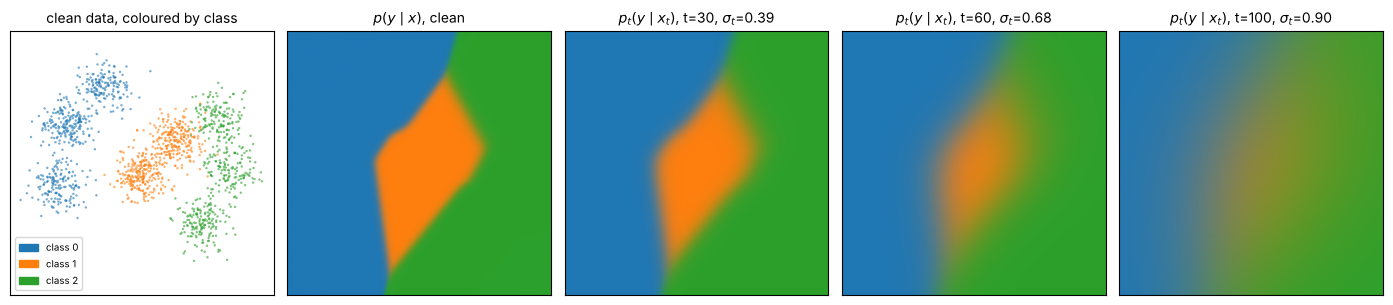

In [4]:
LIM = 3.5
grid_n = 160
gx = torch.linspace(-LIM, LIM, grid_n, dtype=torch.float64)
GX, GY = torch.meshgrid(gx, gx, indexing="xy")
grid_pts = torch.stack([GX.flatten(), GY.flatten()], 1)


def class_rgb_image(abar=None, lim=LIM, n=grid_n):
    """RGB image on [-lim, lim]^2 whose colour is sum_c p_t(c | x) * colour_c (uncertain regions look muddy)."""
    g1 = torch.linspace(-lim, lim, n, dtype=torch.float64)
    pts = torch.stack([a.flatten() for a in torch.meshgrid(g1, g1, indexing="xy")], 1)
    probs = noisy_classifier_logprobs(pts, abar).exp().numpy()
    return (probs @ CLASS_RGB).reshape(n, n, 3)


x_show, comp_show = gmm.sample(1500, return_labels=True, generator=torch.Generator().manual_seed(2))
fig, axes = plt.subplots(1, 5, figsize=(14, 3.1))
dm.scatter2d(x_show, ax=axes[0], lim=LIM, s=3, alpha=0.6, c=CLASS_RGB[comp_class[comp_show.numpy()]],
             title="clean data, coloured by class")
axes[0].legend(handles=[Patch(color=c, label=f"class {i}") for i, c in enumerate(CLASS_COLORS)],
               loc="lower left", fontsize=7)
for ax, t in zip(axes[1:], [None, 30, 60, 100]):
    ab = None if t is None else abar_at(t)
    ax.imshow(class_rgb_image(ab), extent=[-LIM, LIM, -LIM, LIM], origin="lower")
    ax.set_xticks([]), ax.set_yticks([])
    ax.set_title("$p(y\\mid x)$, clean" if t is None else f"$p_t(y\\mid x_t)$, t={t}, $\\sigma_t$={math.sqrt(1 - ab):.2f}")
plt.tight_layout()
plt.show()

On clean data the classifier has sharp decision boundaries. As noise grows, the boundaries blur and the
uncertain (muddy) band widens. The enclosed middle class 1 fades first: at high noise, a point can only be
told to be "left" (class 0) or "right" (class 2). Guidance follows the *gradient* of this map, so at high noise it
gives a gentle, large-scale push (left/right), and at low noise a sharp push concentrated near the boundaries.

Below, Bayes' rule for scores as a picture, for class $y=1$ at $t=40$. Each panel's background is the function
whose log-gradient is drawn: $q_t(x)$, $p_t(y{=}1\mid x)$ and $q_t(x\mid y{=}1)$. The two left fields add up to the
right one, and all three panels use the same arrow scale.

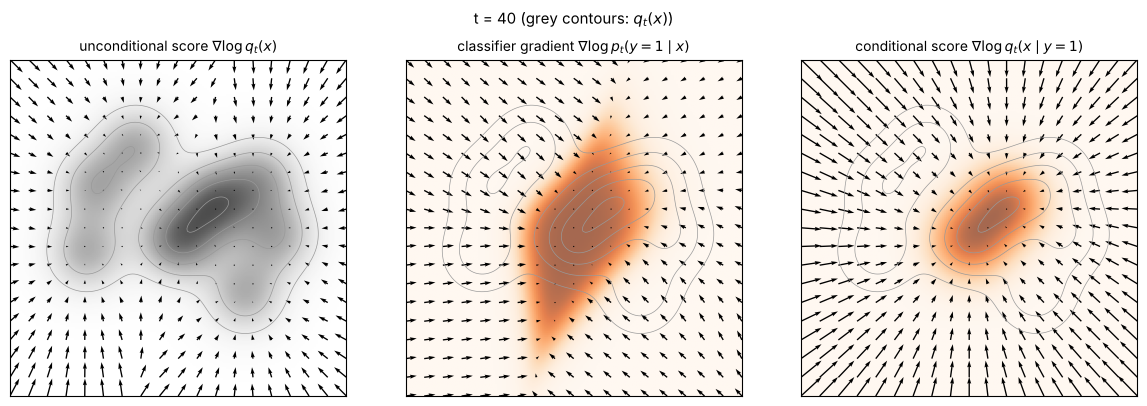

distance r                     : [ 2.  5. 10. 20. 40.]
|grad log p_t(y=1|x)|          : [3.7  4.39 4.42 4.42 4.42]
log p_t(y=1|x)                 : [  -2.4  -13.9  -33.3  -72.3 -150.2]
|unconditional score|          : [  0.3   8.7  23.6  53.5 113.3]


In [5]:
t_q, y_q = 40, 1
ab_q = abar_at(t_q)
full_q, per_class_q = noised_mixtures(ab_q)


def classifier_grad(x, y, abar):
    """grad_x log p_t(y | x_t) by autograd through the exact noise-aware classifier."""
    with torch.enable_grad():                     # also works when called under torch.no_grad()
        xg = x.detach().double().requires_grad_(True)
        out, = torch.autograd.grad(noisy_classifier_logprobs(xg, abar)[:, y].sum(), xg)
    return out


dens_cond = per_class_q[y_q].log_prob(grid_pts).exp().reshape(grid_n, grid_n).numpy()
dens_uncond = full_q.log_prob(grid_pts).exp().reshape(grid_n, grid_n).numpy()
prob_y = noisy_classifier_logprobs(grid_pts, ab_q)[:, y_q].exp().reshape(grid_n, grid_n).numpy()
fields = {   # title: (vector field, background image, colour map)
    "unconditional score $\\nabla\\log q_t(x)$":
        (lambda p: full_q.score(p.double()).float(), dens_uncond, "Greys"),
    "classifier gradient $\\nabla\\log p_t(y{=}1\\mid x)$":
        (lambda p: classifier_grad(p, y_q, ab_q).float(), prob_y, "Oranges"),
    "conditional score $\\nabla\\log q_t(x\\mid y{=}1)$":
        (lambda p: per_class_q[y_q].score(p.double()).float(), dens_cond, "Oranges"),
}
# one common arrow scale (data units per unit of score), chosen from the conditional field
q_pts = torch.stack(torch.meshgrid(torch.linspace(-LIM, LIM, 19), torch.linspace(-LIM, LIM, 19), indexing="xy"), -1).reshape(-1, 2)
arrow_scale = torch.quantile(per_class_q[y_q].score(q_pts.double()).norm(dim=1), 0.75).item() / 0.4
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, (fn, bg, cmap)) in zip(axes, fields.items()):
    ax.imshow(bg, extent=[-LIM, LIM, -LIM, LIM], origin="lower", cmap=cmap, alpha=0.7)
    ax.contour(GX.numpy(), GY.numpy(), dens_uncond, levels=5, colors="0.6", linewidths=0.5)
    dm.plot_vector_field(fn, ax=ax, lim=LIM, n=19, angles="xy", scale_units="xy", scale=arrow_scale, width=0.004)
    ax.set_title(name)
    ax.set_xticks([]), ax.set_yticks([])
plt.suptitle(f"t = {t_q} (grey contours: $q_t(x)$)", y=1.0)
plt.tight_layout()
plt.show()

# how do the two terms scale far from the data? Walk out along the +x axis.
ray = torch.tensor([[r, 0.0] for r in (2.0, 5.0, 10.0, 20.0, 40.0)], dtype=torch.float64)
print("distance r                     :", ray[:, 0].numpy())
print("|grad log p_t(y=1|x)|          :", classifier_grad(ray, y_q, ab_q).norm(dim=1).numpy().round(2))
print("log p_t(y=1|x)                 :", noisy_classifier_logprobs(ray, ab_q)[:, y_q].numpy().round(1))
print("|unconditional score|          :", full_q.score(ray).norm(dim=1).numpy().round(1))

The unconditional score points towards *all* of the probability mass. The classifier gradient is near zero
where class 1 is already certain (dark orange). Everywhere else it points back towards that region, with a
strength that grows near the class and then **levels off**: far from the data the arrows have roughly constant
length. The printout shows why. Along a ray, $\log p_t(y\mid x)$ falls off only *linearly* (doubling $r$ roughly
doubles it), so its gradient saturates. All components share one covariance, which after noising is
$s_t I$ with $s_t=0.12\,\bar\alpha_t+1-\bar\alpha_t$, so the quadratic term $-\|x\|^2/2s_t$ is common to every
component and cancels in $\log q_t(x,y)-\log q_t(x)$. What remains is a difference of log-sum-exps of *affine*
functions of $x$, a soft piecewise-linear discriminant. It is the mixture version of linear discriminant analysis,
where equal-covariance Gaussian classes give exactly linear log-odds (as in logistic regression). The scores, by
contrast, grow linearly with distance, so far out the unconditional score dominates the guidance term. Their sum, the conditional score, points only at
class 1's two components.

## 2 · Classifier guidance

Dhariwal & Nichol (2021) found that conditional samples ($w=1$ below) were not "class-like" enough, and they
introduced a **guidance scale** $w$ on the classifier term:
$$\tilde s_t(x_t,y)=\nabla\log q_t(x_t)+w\,\nabla\log p_t(y\mid x_t),\qquad
\tilde\epsilon(x_t,t,y)=\epsilon(x_t,t)-w\,\sqrt{1-\bar\alpha_t}\;\nabla_{x_t}\log p_t(y\mid x_t).\tag{2}$$
At $t=0$, $\tilde s_0$ is exactly the score of the **tilted** density
$$p_w(x\mid y)\;\propto\;p(x)\,p(y\mid x)^{w}\;\propto\;p(x\mid y)\,p(y\mid x)^{w-1}.$$
This is a **tempered (power) likelihood**, a familiar object in Bayesian inference. $w=0$ ignores $y$, $w=1$ is the
true conditional, and $w>1$ up-weights points the classifier is sure about: "prototypical" members of the class,
away from regions shared with other classes. Section 4 shows that "at $t=0$" is carrying a lot of weight in that
statement.

**Implementation details that matter in practice:**
* The classifier must be trained on *noisy* inputs at every $t$ (it models $p_t$, not $p_0$) and must be told $t$.
  An off-the-shelf image classifier does not work (Exercise 3).
* Each sampling step needs $\nabla_x\log p_t(y\mid x_t)$, one extra forward *and* backward pass. Samplers run
  under `torch.no_grad()`, so autograd must be switched back on locally.
* Summing the per-sample log-probabilities before `autograd.grad` yields all per-sample gradients in one call,
  because samples do not interact.
* Input-gradients of neural classifiers can be "adversarial": they raise $p(y\mid x)$ by imperceptible
  perturbations instead of semantic changes. Training on noisy inputs helps. Avoiding the classifier altogether
  (Section 3) helps more.

Here the classifier is the exact Bayes classifier and the "network" is the exact score, so the only
approximation left is the sampler. Both are wrapped as modules with the usual `model(x, t, y)` signature, so the
DDPM ancestral sampler from notebook 02 (`dm.ddpm_sample`) runs them unchanged.

In [6]:
class ExactDenoiser(nn.Module):
    """The ideal conditional eps-network for the labelled GMM:
    eps*(x_t, t, y) = -sqrt(1 - abar_t) * grad log q_t(x_t | y);  y = NULL gives the unconditional eps*(x_t, t)."""

    n_classes = N_CLASSES

    def __init__(self, schedule=sched2d):
        super().__init__()
        self.schedule = schedule

    def forward(self, x, t, y=None):
        t_int = int(t.reshape(-1)[0])                      # all samplers here use one t per batch
        full, per_class = noised_mixtures(abar_at(t_int, self.schedule))
        x64 = x.detach().to("cpu", torch.float64)
        score = full.score(x64)
        if y is not None:
            y = y.cpu()
            for c in range(N_CLASSES):                      # label NULL keeps the unconditional score
                m = y == c
                if m.any():
                    score[m] = per_class[c].score(x64[m])
        sigma = float(self.schedule.sqrt_one_minus_alpha_bars[t_int])
        return (-sigma * score).to(x.device, x.dtype)


class ClassifierGuidedEps(nn.Module):
    """Classifier guidance, eq. (2): eps_u(x_t) - w sqrt(1 - abar_t) grad_x log p_t(y | x_t),
    with the gradient taken by autograd through the exact noise-aware classifier."""

    n_classes = N_CLASSES

    def __init__(self, w: float, schedule=sched2d):
        super().__init__()
        self.w, self.schedule = w, schedule

    def forward(self, x, t, y):
        t_int = int(t.reshape(-1)[0])
        ab = abar_at(t_int, self.schedule)
        x64 = x.detach().to("cpu", torch.float64)
        with torch.enable_grad():                           # samplers run under no_grad: switch autograd back on
            x64.requires_grad_(True)
            log_py = noisy_classifier_logprobs(x64, ab).gather(1, y.cpu()[:, None]).sum()
            grad_log_py, = torch.autograd.grad(log_py, x64)  # summing gives every per-sample gradient at once
        score = noised_mixtures(ab)[0].score(x64.detach()) + self.w * grad_log_py
        sigma = float(self.schedule.sqrt_one_minus_alpha_bars[t_int])
        return (-sigma * score).to(x.device, x.dtype)


def sample_2d(model, labels, w=1.0, seed=0, sampler="ddpm", schedule=sched2d):
    """len(labels) samples. `w` is passed to dmtools' CFG (eps_u + w (eps_c - eps_u)); a module that
    applies guidance itself is called with w=1. Same seed => same x_T and the same sampler noise."""
    labels = labels.to(device)
    x_T = torch.randn(len(labels), 2, device=device, generator=make_gen(seed))
    if sampler == "ddpm":
        x = dm.ddpm_sample(model, schedule, x_T.shape, y=labels, guidance_scale=w, x_T=x_T,
                           generator=make_gen(seed + 1))
    else:   # deterministic DDIM through every time step (the probability-flow ODE, notebook 04)
        x = dm.ddim_sample(model, schedule, x_T.shape, n_steps=schedule.T, y=labels, guidance_scale=w, x_T=x_T)
    return x.cpu()


labels_2d = torch.arange(N_CLASSES).repeat_interleave(N_PER_CLASS_2D)    # N_PER_CLASS_2D of each class
W_LIST = [0.0, 1.0, 3.0, 10.0]
t0 = time.time()
cg_samples = {w: sample_2d(ClassifierGuidedEps(w), labels_2d, seed=10) for w in W_LIST}
print(f"classifier guidance: {len(W_LIST)} x {len(labels_2d)} samples in {time.time() - t0:.1f}s")

# --- Check: w = 1 must reproduce the class-conditional distributions, w = 0 the unconditional one.
gen_ref = torch.Generator().manual_seed(3)
true_cond = torch.cat([class_gmms[c].sample(N_PER_CLASS_2D, generator=gen_ref) for c in range(N_CLASSES)])
true_cond_2 = torch.cat([class_gmms[c].sample(N_PER_CLASS_2D, generator=gen_ref) for c in range(N_CLASSES)])
true_uncond = gmm.sample(len(labels_2d), generator=gen_ref)


def mmd_by_class(a, b, labels):
    """Mean over classes of MMD^2 between the class-c rows of a and of b."""
    return np.mean([dm.mmd_rbf(a[labels == c], b[labels == c]) for c in range(N_CLASSES)])


print(f"MMD^2 per class, w=1 vs true p(x|y)     : {mmd_by_class(cg_samples[1.0], true_cond, labels_2d):.5f}")
print(f"MMD^2 per class, true vs true (noise floor): {mmd_by_class(true_cond_2, true_cond, labels_2d):.5f}")
print(f"MMD^2, w=0 vs true p(x)                  : {dm.mmd_rbf(cg_samples[0.0], true_uncond):.5f}")

classifier guidance: 4 x 3000 samples in 5.3s


MMD^2 per class, w=1 vs true p(x|y)     : 0.01158


MMD^2 per class, true vs true (noise floor): 0.01103


MMD^2, w=0 vs true p(x)                  : 0.00294


At $w=1$ the guided sampler reproduces $p(x\mid y)$ to within the MMD noise floor, so Bayes' rule plus an exact
noise-aware classifier *is* a conditional model. Now the interesting part, $w>1$. We score each set of samples with
two numbers:
* **fidelity**: the mean *clean* classifier probability $p(y\mid x)$ of the requested class, and the accuracy
  $\arg\max_c p(c\mid x)=y$;
* **diversity**: the mean pairwise distance between samples of the same class, divided by the same quantity
  for true samples of that class (1 = as diverse as the data).

To tell what belongs to the *target* and what to the *sampler*, we also draw exact samples from the tilted density
$p_w\propto p(x)\,p(y\mid x)^w$ itself. It is not a Gaussian mixture, but in 2-D we can tabulate it on a fine grid
and sample from it: pick a cell in proportion to its mass, then a uniform point inside the cell.

   w   samples from      accuracy  mean p(y|x)   rel. diversity: class 0  class 1  class 2
  0.0   guided sampler      0.347       0.346                     1.59     2.55     1.57
  0.0   exact p_w           0.334       0.334                     1.57     2.53     1.57
  1.0   guided sampler      0.991       0.985                     0.98     1.02     0.98
  1.0   exact p_w           0.987       0.982                     1.01     1.02     1.02
  3.0   guided sampler      1.000       0.999                     0.93     0.88     0.92
  3.0   exact p_w           1.000       0.994                     1.01     1.00     1.00
 10.0   guided sampler      1.000       1.000                     0.88     0.77     0.84
 10.0   exact p_w           1.000       0.998                     1.01     0.96     1.00

fraction of each class's samples in each of its components (true p(x|y): equal shares)
                         class 0                             | class 1                 | class 2             

w =  1.0  guided sampler        0.35        0.31        0.33 |        0.48        0.52 |        0.32        0.31        0.37
w =  1.0  exact p_w             0.33        0.33        0.33 |        0.50        0.50 |        0.33        0.33        0.33
w =  3.0  guided sampler        0.43        0.24        0.34 |        0.57        0.43 |        0.20        0.33        0.47
w =  3.0  exact p_w             0.33        0.33        0.33 |        0.52        0.48 |        0.31        0.34        0.34
w = 10.0  guided sampler        0.49        0.18        0.34 |        0.70        0.30 |        0.11        0.35        0.54
w = 10.0  exact p_w             0.33        0.33        0.33 |        0.54        0.46 |        0.29        0.36        0.35


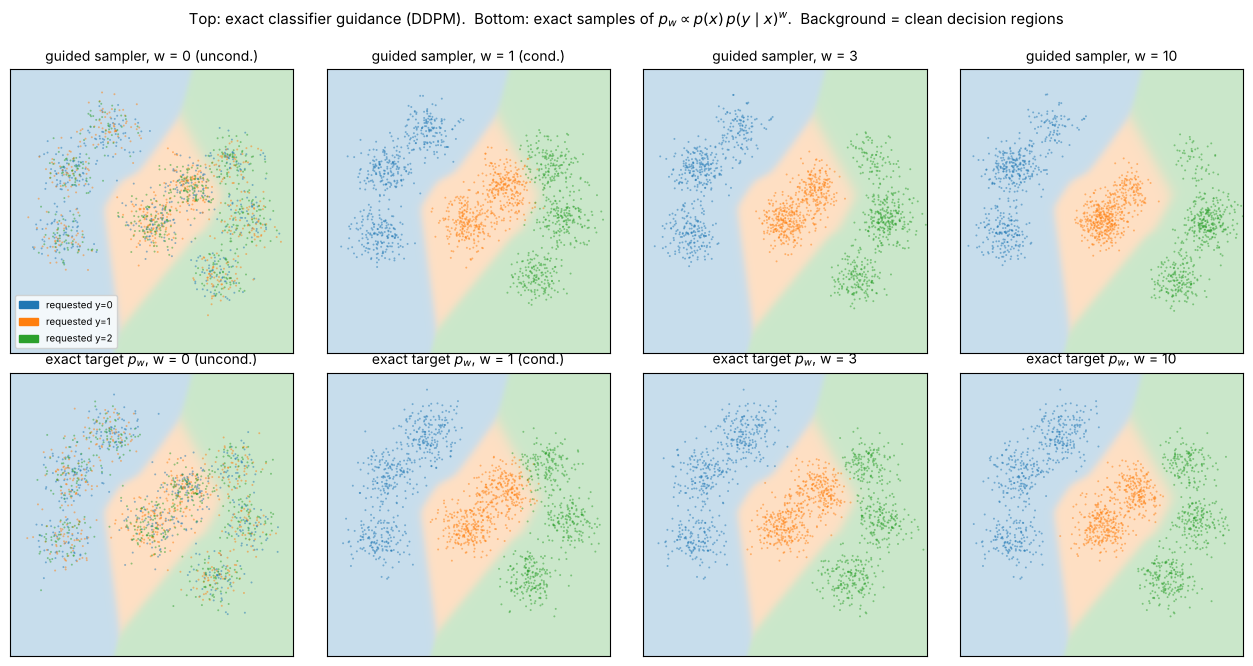

In [7]:
def tilted_density_grid(y, w, lim=4.5, n=300):
    """Exact p_w(x|y) ∝ p(x) p(y|x)^w on a regular n x n grid: (cell centres, cell probabilities, spacing)."""
    g1 = torch.linspace(-lim, lim, n, dtype=torch.float64)
    X, Y = torch.meshgrid(g1, g1, indexing="xy")
    pts = torch.stack([X.flatten(), Y.flatten()], 1)
    log_joint = class_log_joint(pts)
    log_px = torch.logsumexp(log_joint, 1)
    log_tilted = log_px + w * (log_joint[:, y] - log_px)          # log p(x) + w log p(y|x)
    return pts, torch.softmax(log_tilted, 0), (g1[1] - g1[0]).item()


def sample_from_grid(pts, probs, h, n, seed):
    """Draw from the tabulated density: cell ~ probs, then uniform within the cell."""
    g = torch.Generator().manual_seed(seed)
    idx = torch.multinomial(probs, n, replacement=True, generator=g)
    return (pts[idx] + (torch.rand(n, 2, generator=g, dtype=torch.float64) - 0.5) * h).float()


REF_DIV_2D = [torch.pdist(true_cond[labels_2d == c]).mean().item() for c in range(N_CLASSES)]


def fidelity_diversity_2d(x, labels):
    """(accuracy, mean p(y|x), relative within-class diversity per class) under the exact clean classifier."""
    probs = noisy_classifier_logprobs(x.double()).exp()
    conf = probs[torch.arange(len(x)), labels].mean().item()
    acc = (probs.argmax(1) == labels).float().mean().item()
    div = [torch.pdist(x[labels == c]).mean().item() / REF_DIV_2D[c] for c in range(N_CLASSES)]
    return acc, conf, div


def component_occupancy(x, c):
    """Fraction of the samples x (requested class c) that belong to each of class c's components."""
    k = class_gmms[c].responsibilities(x).argmax(1)
    return torch.bincount(k, minlength=class_gmms[c].K).float() / len(x)


def grid_occupancy(pts, probs, c):
    """The same fractions, computed exactly for a tabulated density (mass of the cells assigned to each component)."""
    k = class_gmms[c].responsibilities(pts).argmax(1)
    return torch.zeros(class_gmms[c].K, dtype=torch.float64).index_add_(0, k, probs).float()


# exact p_w for every class and w: tabulated once, then sampled (N_PER_CLASS_2D per class, like the guided runs)
pw_grids = {(w, c): tilted_density_grid(c, w) for w in W_LIST for c in range(N_CLASSES)}
pw_samples = {w: torch.cat([sample_from_grid(*pw_grids[(w, c)], N_PER_CLASS_2D, seed=40 + c) for c in range(N_CLASSES)])
              for w in W_LIST}

print("   w   samples from      accuracy  mean p(y|x)   rel. diversity: class 0  class 1  class 2")
for w in W_LIST:
    for name, x in [("guided sampler", cg_samples[w]), ("exact p_w", pw_samples[w])]:
        acc, conf, div = fidelity_diversity_2d(x, labels_2d)
        print(f"{w:5.1f}   {name:15s}   {acc:7.3f}   {conf:9.3f}   {'':15s}{div[0]:7.2f}  {div[1]:7.2f}  {div[2]:7.2f}")

print("\nfraction of each class's samples in each of its components (true p(x|y): equal shares)")
comp_hdr = " | ".join(" ".join(f"({m[0]:4.1f},{m[1]:4.1f})" for m in class_gmms[c].means.numpy())
                      for c in range(N_CLASSES))
print(f"{'':25s}" + " | ".join(f"{'class ' + str(c):<{12 * class_gmms[c].K - 1}s}" for c in range(N_CLASSES)))
print(f"{'component mean':25s}{comp_hdr}")
for w in W_LIST[1:]:                                       # w = 0 ignores the label: not meaningful
    rows = {"guided sampler": [component_occupancy(cg_samples[w][labels_2d == c], c) for c in range(N_CLASSES)],
            "exact p_w": [grid_occupancy(*pw_grids[(w, c)][:2], c) for c in range(N_CLASSES)]}
    for name, occ_list in rows.items():
        occ_txt = " | ".join(" ".join(f"{v:11.2f}" for v in o) for o in occ_list)
        print(f"w = {w:4.1f}  {name:15s}{occ_txt}")

clean_rgb = class_rgb_image(None)
SHOW = slice(None, None, 2)          # plot every 2nd sample (class-balanced: labels are sorted); metrics use all
fig, axes = plt.subplots(2, len(W_LIST), figsize=(3.2 * len(W_LIST), 6.6))
for j, w in enumerate(W_LIST):
    for i, (name, s) in enumerate([("guided sampler", cg_samples[w]), ("exact target $p_w$", pw_samples[w])]):
        ax = axes[i, j]
        ax.imshow(clean_rgb, extent=[-LIM, LIM, -LIM, LIM], origin="lower", alpha=0.25)
        dm.scatter2d(s[SHOW], ax=ax, lim=LIM, s=2, alpha=0.5, c=CLASS_RGB[labels_2d[SHOW].numpy()])
        ax.set_title(f"{name}, w = {w:g}" + (" (uncond.)" if w == 0 else " (cond.)" if w == 1 else ""))
axes[0, 0].legend(handles=[Patch(color=c, label=f"requested y={i}") for i, c in enumerate(CLASS_COLORS)],
                  loc="lower left", fontsize=7)
plt.suptitle("Top: exact classifier guidance (DDPM).  Bottom: exact samples of $p_w\\propto p(x)\\,p(y\\mid x)^w$.  "
             "Background = clean decision regions", y=1.0)
plt.tight_layout()
plt.show()

* $w=0$ ignores the request: each colour is spread over all eight components. (Its "within-class" diversity is
  that of the whole mixture, hence above 1.)
* $w=1$ samples each class correctly, including the few class-1 points (orange) that fall into the other
  classes' territory.
* $w>1$: fidelity goes to 1 and diversity drops. But compare the two rows. The **target** $p_w$ barely differs
  from $p(x\mid y)$ here. Its blobs are well separated, so $p(y\mid x)\approx1$ wherever they have mass, and the
  tilt $p(y\mid x)^{w-1}$ only trims the thin tails that reach into other classes' territory. That alone is
  enough to push fidelity to 1, while its component shares stay close to equal and its diversity stays close
  to 1 (the "exact p_w" rows). The **guided samples** behave differently. Each blob keeps roughly its width, but the
  **components nearest another class lose samples**: class 1's right-hand component at $(0.9, 0.6)$, class 2's
  upper one at $(2.0, 1.2)$, class 0's top one at $(-1.0, 2.0)$. Most of the diversity loss comes from this
  re-weighting.

So the re-weighting is not in the target. The guided *dynamics* produce it, even though every score and every
classifier probability here is exact. At intermediate noise the noisy classifier is uncertain over whole blobs,
and $w$ times its gradient pushes trajectories away from the other classes *before* they commit to a component.
This gap between what guidance is supposed to sample and what it does sample is the subject of Section 4.

## 3 · Classifier-free guidance

Classifier guidance needs a second network, trained on noisy data at every $t$, and a backward pass through it
at every step. Ho & Salimans (2022) noticed that Bayes' rule can be run *backwards* to get the classifier
gradient from a conditional model:
$$\nabla\log p_t(y\mid x_t)=\nabla\log q_t(x_t\mid y)-\nabla\log q_t(x_t)
\;\approx\;-\frac{\epsilon_\theta(x_t,t,y)-\epsilon_\theta(x_t,t,\varnothing)}{\sqrt{1-\bar\alpha_t}} .$$
Plug this **implicit classifier** into eq. (2):
$$\boxed{\;\tilde\epsilon=\epsilon_u+w\,(\epsilon_c-\epsilon_u)=(1-w)\,\epsilon_u+w\,\epsilon_c\;}
\qquad\Longleftrightarrow\qquad \tilde s_t=\nabla\log\big[q_t(x_t)^{1-w}\,q_t(x_t\mid y)^{w}\big],$$
with $\epsilon_c=\epsilon_\theta(x_t,t,y)$ and $\epsilon_u=\epsilon_\theta(x_t,t,\varnothing)$. For $w>1$ this
*extrapolates* from the unconditional prediction past the conditional one.

**One network does both jobs** thanks to **label dropout**: during training, the label is replaced by the null
token $\varnothing$ (here index `n_classes`) with probability $p_\text{uncond}$, typically 0.1–0.2. The same
weights then learn $\epsilon_c$ and $\epsilon_u$, and the "classifier" is automatically noise-aware.
For text-to-image models, $y$ is a text embedding and $\varnothing$ is the embedding of the empty prompt.

**Cost:** two network evaluations (NFE) per sampling step. Implementations put the conditional and
unconditional inputs into *one* batch of size $2B$. That costs the same arithmetic as two calls, but has better
hardware utilisation.

First, with exact scores, classifier guidance and CFG are the *same* thing:

In [8]:
exact = ExactDenoiser()
x_chk = 2.5 * torch.randn(1000, 2)
y_chk = torch.randint(0, N_CLASSES, (1000,))
max_diff = 0.0
for t in [3, 60, 180]:
    t_vec = torch.full((1000,), t)
    eps_c, eps_u = exact(x_chk, t_vec, y_chk), exact(x_chk, t_vec, torch.full_like(y_chk, NULL))
    for w in [0.0, 3.0, 10.0]:
        cfg = eps_u + w * (eps_c - eps_u)
        cg = ClassifierGuidedEps(w)(x_chk, t_vec, y_chk)
        max_diff = max(max_diff, ((cfg - cg).abs().max() / cg.abs().max()).item())
print(f"exact CFG vs exact classifier guidance: max relative difference {max_diff:.1e}")
assert max_diff < 1e-4

exact CFG vs exact classifier guidance: max relative difference 7.7e-07


So with *perfect* networks the two methods are identical, and any difference in practice comes from what is
learned. Now the two pieces of CFG, written out: the training loss with label dropout, and the guided noise
prediction (with an optional *negative* label instead of $\varnothing$, used in Section 7). Each is checked
against its `dmtools` counterpart.

In [9]:
def cfg_training_loss(model, x0, y, schedule, p_uncond):
    """Denoising loss with label dropout: with prob. p_uncond the label is replaced by the null token."""
    B = x0.shape[0]
    t = torch.randint(0, schedule.T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = schedule.q_sample(x0, t, noise)
    drop = torch.rand(B, device=x0.device) < p_uncond                       # label dropout
    y_in = torch.where(drop, torch.full_like(y, model.n_classes), y)
    return F.mse_loss(model(xt, t, y_in), noise)


@torch.no_grad()
def cfg_eps(model, x, t, y, w, y_neg=None):
    """Guided noise prediction eps_neg + w (eps_c - eps_neg), where eps_neg uses the null label unless a
    negative label y_neg is given. One batched forward pass of size 2B (= 2 NFE)."""
    if y_neg is None:
        y_neg = torch.full_like(y, model.n_classes)
    out = model(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, y_neg])).float()
    eps_c, eps_neg = out.chunk(2)
    return eps_neg + w * (eps_c - eps_neg)


# training data: 50k labelled points of the mixture
x_train, comp = gmm.sample(50_000, return_labels=True, generator=torch.Generator().manual_seed(0))
y_train = torch.as_tensor(comp_class)[comp]
P_UNCOND = 0.15
cfg_mlp = dm.MLPDenoiser(data_dim=2, hidden=128, n_blocks=3, n_classes=N_CLASSES).to(device)

# check both functions against dmtools (same random draws => same numbers)
xb, yb = x_train[:256].to(device), y_train[:256].to(device)
torch.manual_seed(0)
mine = cfg_training_loss(cfg_mlp, xb, yb, sched2d, P_UNCOND)
torch.manual_seed(0)
ref = dm.diffusion_loss(cfg_mlp, xb, sched2d, y=yb, p_uncond=P_UNCOND)
tb = torch.full((256,), 100, device=device)
eps_ref, _ = dm.model_predictions(cfg_mlp, xb, tb, sched2d, y=yb, guidance_scale=4.0)
print(f"loss: mine {mine.item():.6f} | dmtools {ref.item():.6f};   "
      f"guided eps max |diff| = {(cfg_eps(cfg_mlp, xb, tb, yb, 4.0) - eps_ref).abs().max().item():.1e}")
assert torch.allclose(mine, ref) and torch.allclose(cfg_eps(cfg_mlp, xb, tb, yb, 4.0), eps_ref, atol=1e-5)

loss: mine 1.713289 | dmtools 1.713289;   guided eps max |diff| = 0.0e+00


Now train one network with label dropout. When `dm.train_diffusion` (notebook 05) receives `labels` and
`p_uncond`, its loss is exactly our `cfg_training_loss` (via `dm.diffusion_loss`, checked above).

In [10]:
t0 = time.time()
# amp=False: a tiny MLP gains nothing from bfloat16, and the eps_c - eps_u analysis below wants full precision
# (with amp=None, dmtools would switch bf16 on automatically on CUDA GPUs only, so results would depend on the device)
run2d = dm.train_diffusion(cfg_mlp, x_train, sched2d, labels=y_train, p_uncond=P_UNCOND, steps=STEPS_2D,
                           batch_size=512, lr=1e-3, warmup=200, progress=False, log_every=max(1, STEPS_2D // 3),
                           amp=False)
cfg_mlp_ema = run2d["ema"].model
print(f"trained {STEPS_2D} steps in {time.time() - t0:.0f}s")

step   1000 | loss 0.2720


step   2000 | loss 0.2184


step   3000 | loss 0.2174
trained 3000 steps in 25s


How accurate are the learned $\epsilon_c$, $\epsilon_u$ and, above all, their **difference** (the implicit
classifier gradient that guidance multiplies by $w$)? We compare with the exact values on noised training data.

In [11]:
def rel_err(a, b):
    """E||a - b||^2 / E||b||^2"""
    return ((a - b).pow(2).sum(1).mean() / b.pow(2).sum(1).mean()).item()


x_ev, y_ev = x_train[:4000].to(device), y_train[:4000].to(device)
null_ev = torch.full_like(y_ev, NULL)
print("   t    rel. err eps_c   rel. err eps_u   rel. err (eps_c - eps_u)")
with torch.no_grad():
    for t in [5, 30, 80, 150]:
        t_vec = torch.full((len(x_ev),), t, device=device)
        xt = sched2d.q_sample(x_ev, t_vec)
        learned = [cfg_mlp_ema(xt, t_vec, y_ev), cfg_mlp_ema(xt, t_vec, null_ev)]
        truth = [exact(xt, t_vec, y_ev), exact(xt, t_vec, null_ev)]
        print(f"{t:4d}   {rel_err(learned[0], truth[0]):14.4f}   {rel_err(learned[1], truth[1]):14.4f}"
              f"   {rel_err(learned[0] - learned[1], truth[0] - truth[1]):22.4f}")

   t    rel. err eps_c   rel. err eps_u   rel. err (eps_c - eps_u)
   5           0.1451           0.5174                   4.2726
  30           0.0146           0.1450                   0.2416
  80           0.0004           0.0027                   0.0061
 150           0.0002           0.0004                   0.0146


The two predictions are individually fairly accurate, except $\epsilon_u$ at the lowest noise level. Their
*difference*, however, is a small quantity obtained by subtracting two large ones. At low noise the two agree
everywhere except near class boundaries, and at high noise the classifier is nearly uniform. So the relative
error of the difference is much larger than that of either term, and guidance multiplies exactly this error by
$w$. **Model errors are amplified by the guidance scale.**

Now we sample with the learned CFG model, using the **same** $x_T$ and sampler noise (seed) as the exact
classifier-guidance samples of Section 2. Exact CFG *is* exact classifier guidance (checked above), so those
samples serve as the exact reference, and in the figure the difference between rows is model error only.

**A statistics gotcha.** Shared noise ("common random numbers") is ideal for eyeballing differences, but it makes
the two sample sets positively correlated, and that biases a two-sample statistic such as MMD *downwards*. A
paired MMD cannot be compared with a noise floor computed from independent samples. For the table we therefore
compare the learned samples with an *independent* exact draw (another seed), and take as the floor the MMD
between two independent exact draws.

sampling: 24.4s
   w   MMD^2(learned, exact)   MMD^2(exact, exact) = noise floor   [both: independent draws]


  0.0                0.02446                             0.01197


  1.0                0.01544                             0.01036


  3.0                0.05058                             0.01067


 10.0                0.60223                             0.01116


(for contrast, w = 1 with shared noise: 0.00768, deceptively small)


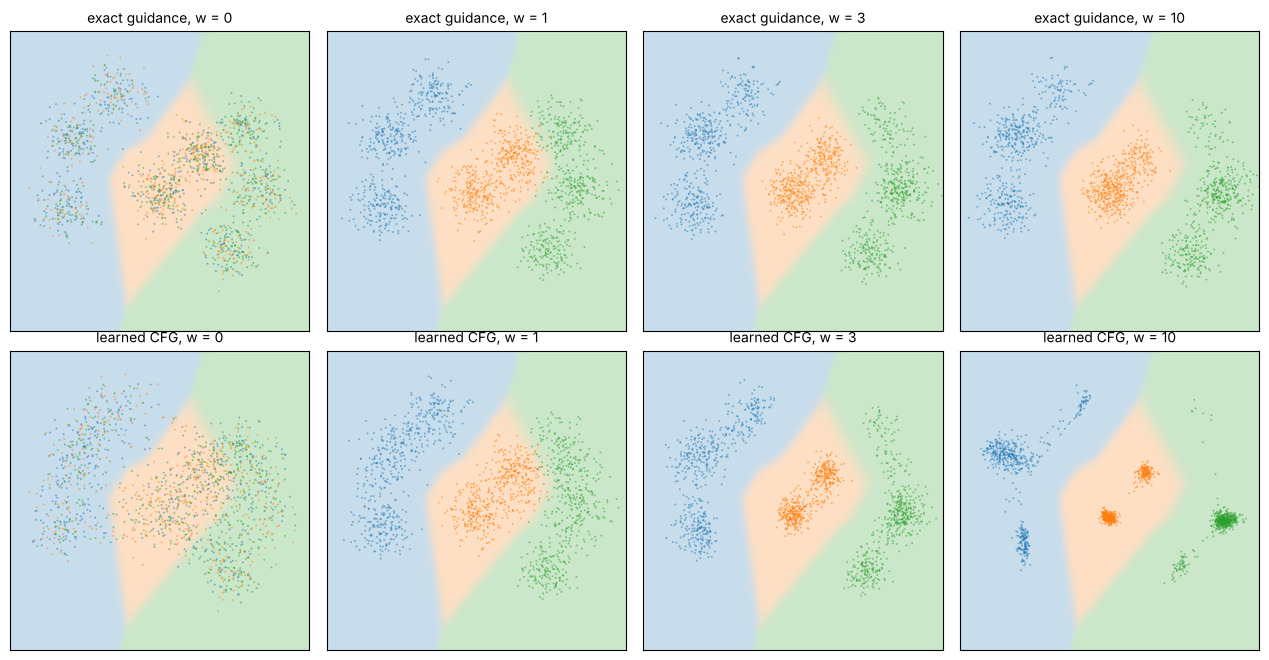

In [12]:
t0 = time.time()
learned_samples = {w: sample_2d(cfg_mlp_ema, labels_2d, w=w, seed=10) for w in W_LIST}
exact_shared = cg_samples                       # exact guidance, seed 10: same noise as learned_samples
exact_indep = {w: sample_2d(exact, labels_2d, w=w, seed=11) for w in W_LIST}   # exact CFG, independent noise
print(f"sampling: {time.time() - t0:.1f}s")
print("   w   MMD^2(learned, exact)   MMD^2(exact, exact) = noise floor   [both: independent draws]")
for w in W_LIST:
    print(f"{w:5.1f}   {mmd_by_class(learned_samples[w], exact_indep[w], labels_2d):20.5f}"
          f"   {mmd_by_class(exact_shared[w], exact_indep[w], labels_2d):33.5f}")
print(f"(for contrast, w = 1 with shared noise: {mmd_by_class(learned_samples[1.0], exact_shared[1.0], labels_2d):.5f},"
      f" deceptively small)")

fig, axes = plt.subplots(2, len(W_LIST), figsize=(3.2 * len(W_LIST), 6.6))
for j, w in enumerate(W_LIST):
    for i, (name, s) in enumerate([("exact guidance", exact_shared[w]), ("learned CFG", learned_samples[w])]):
        axes[i, j].imshow(clean_rgb, extent=[-LIM, LIM, -LIM, LIM], origin="lower", alpha=0.25)
        dm.scatter2d(s[SHOW], ax=axes[i, j], lim=LIM, s=2, alpha=0.5, c=CLASS_RGB[labels_2d[SHOW].numpy()],
                     title=f"{name}, w = {w:g}")
plt.tight_layout()
plt.show()

At $w\le1$ the learned model is close to the exact samples, but measurably above the noise floor: the learned
$\epsilon$ carries some error even without guidance (see $\epsilon_c$ and $\epsilon_u$ at small $t$ in the table
above). With growing $w$ the gap widens quickly, and at $w=10$ the learned CFG does something exact guidance does
*not* do: it **shrinks every mode** into a tight clump. Look at the $w=0$ panels for the reason. The learned *unconditional* samples are visibly blurrier than
the exact ones. The unconditional branch is the under-fitted one: it is trained only on the 15% of examples
whose label was dropped, and it has the harder, 8-mode distribution to learn (see its error at small $t$ in the
table above). So its density is too wide. Take one Gaussian mode with true variance $\sigma^2$, and suppose $\epsilon_u$ implies a wider
$\sigma_b^2>\sigma^2$. The guided score is
$$w\Big(-\frac{x-\mu}{\sigma^2}\Big)+(1-w)\Big(-\frac{x-\mu}{\sigma_b^2}\Big)
=-(x-\mu)\Big[\frac{w}{\sigma^2}-\frac{w-1}{\sigma_b^2}\Big],$$
a precision larger than $1/\sigma^2$ for every $w>1$. For example, $\sigma_b^2=1.5\,\sigma^2$ and $w=10$ give
precision $4/\sigma^2$, i.e. half the standard deviation. **Guidance extrapolates away from the unconditional
model's errors**, so an over-smoothed $\epsilon_u$ turns into over-sharpened samples. Part of the
"sharpening" practitioners attribute to guidance comes from this effect.

## 4 · Advanced: guidance does not sample $p(x)\,p(y\mid x)^w$

> It is tempting to read guidance as "sampling the tempered posterior $p_w(x\mid y)\propto p(x)p(y\mid x)^w$".
> That reading is **wrong in general for $w\notin\{0,1\}$**, even with perfect networks.

**Why.** A reverse-time sampler is guaranteed to produce the target $p_w$ if the field it follows at every noise
level $t$ is the score of the *forward-noised* target, $q^w_t=p_w * \mathcal N(0,\cdot)$ (after scaling by
$\sqrt{\bar\alpha_t}$). The guided field is not that score. It is
$$\tilde s_t=\nabla\log\big[q_t(x)^{1-w}\,q_t(x\mid y)^{w}\big],$$
i.e. we noise $p(x)$ and $p(x\mid y)$ *separately* and then take the geometric mixture. But noising is a
convolution, and convolution does not in general commute with powers and products:
$$\big(f^{1-w}g^{w}\big)*k\;\neq\;(f*k)^{1-w}\,(g*k)^{w}\qquad\text{in general, for } w\notin\{0,1\}.$$
(There are exceptions. For two Gaussians $f,g$ with the *same* covariance both sides are proportional to the same
Gaussian, and guidance is an exact extrapolation of the mean. The mismatch comes from the mixture structure of
$p(x)$.)
So in general $\tilde s_t$ equals $\nabla\log q^w_t$ only at $t=0$, and at intermediate $t$ the family
$\{q_t^{1-w}q_t(\cdot\mid y)^w\}_t$ is not the diffusion of any distribution. Two consequences:
1. guided samples are **not** distributed as $p_w$;
2. the stochastic sampler (DDPM, the reverse SDE) and the deterministic one (DDIM, the probability-flow ODE),
   which agree whenever the field is a genuine score family (notebook 04), now **disagree**.

We can check both claims exactly, with the tabulated $p_w$ of Section 2. We focus on class 0, where
Section 2 showed that $p_w$ hardly differs from $p(x\mid y{=}0)$, and compare DDPM and DDIM.

In [13]:
Y_TILT, W_TILT = 0, 6.0
N_TILT = 3 * N_PER_CLASS_2D
lab_tilt = torch.full((N_TILT,), Y_TILT)
print("MMD^2 to exact samples of p_w(x|y=%d):" % Y_TILT)
print("   w    DDPM + guidance   DDIM + guidance   noise floor (p_w vs p_w)")
tilt = {}
for w in [1.0, 3.0, W_TILT]:
    pts_w, probs_w, h_w = tilted_density_grid(Y_TILT, w)
    ref_a = sample_from_grid(pts_w, probs_w, h_w, N_TILT, seed=1)
    ref_b = sample_from_grid(pts_w, probs_w, h_w, N_TILT, seed=2)
    s_ddpm = sample_2d(exact, lab_tilt, w=w, seed=20, sampler="ddpm")
    s_ddim = sample_2d(exact, lab_tilt, w=w, seed=20, sampler="ddim")
    tilt[w] = dict(pts=pts_w, probs=probs_w, ref=ref_a, ddpm=s_ddpm, ddim=s_ddim)
    print(f"{w:5.1f}   {dm.mmd_rbf(s_ddpm, ref_a):15.5f}   {dm.mmd_rbf(s_ddim, ref_a):15.5f}"
          f"   {dm.mmd_rbf(ref_b, ref_a):15.5f}")

MMD^2 to exact samples of p_w(x|y=0):
   w    DDPM + guidance   DDIM + guidance   noise floor (p_w vs p_w)


  1.0           0.00219           0.00293           0.00224


  3.0           0.03882           0.40000           0.00221


  6.0           0.08042           0.99697           0.00228


At $w=1$ (the control) both samplers hit the noise floor. The machinery is exact. For $w>1$, both guided
samplers are far from $p_w$, many times the noise floor, and DDIM is much further away than DDPM. Let us look.

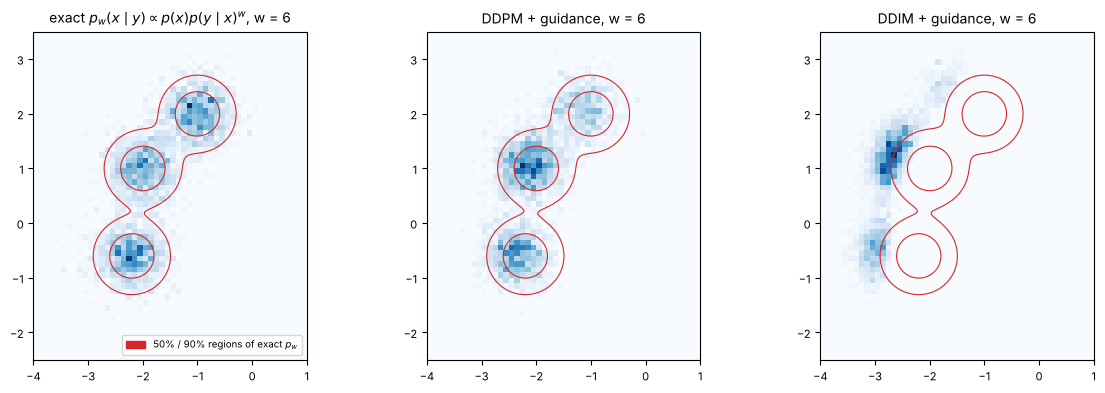

In [14]:
def hdr_levels(probs, masses=(0.9, 0.5)):
    """Density thresholds of the highest-density regions holding the given probability masses (ascending)."""
    p = np.sort(probs)[::-1]
    return sorted(p[np.searchsorted(np.cumsum(p), m)] for m in masses)


tw = tilt[W_TILT]
dens = tw["probs"].reshape(300, 300).numpy()
g300 = np.linspace(-4.5, 4.5, 300)
bins = np.linspace(-4.5, 4.5, 91)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, key, name in zip(axes, ["ref", "ddpm", "ddim"],
                         ["exact $p_w(x\\mid y)\\propto p(x)p(y\\mid x)^w$", "DDPM + guidance", "DDIM + guidance"]):
    s = tw[key].numpy()
    ax.hist2d(s[:, 0], s[:, 1], bins=[bins, bins], cmap="Blues")
    ax.contour(g300, g300, dens, levels=hdr_levels(dens.ravel()), colors="tab:red", linewidths=0.8)
    ax.set(xlim=(-4.0, 1.0), ylim=(-2.5, 3.5), aspect="equal", title=f"{name}, w = {W_TILT:g}")
axes[0].legend(handles=[Patch(color="tab:red", label="50% / 90% regions of exact $p_w$")], loc="lower right",
               fontsize=7)
plt.tight_layout()
plt.show()

Class 0 is well separated from the others, so $p(y{=}0\mid x)\approx1$ wherever class 0 has mass. The tilt
$p(y\mid x)^{w-1}$ then barely changes anything, and $p_w$ looks just like $p(x\mid y{=}0)$: three equal blobs.
Guidance does something quite different. The decisive pushes happen at **intermediate-to-high noise**, where
the noisy classifier is still uncertain and its gradient, multiplied by $w$, drives samples away from the other
classes (to the left here). Those early pushes decide *which* component a sample ends up in, and they cannot be
undone later.
The ODE (DDIM) follows the distorted field deterministically and squeezes the samples into narrow streaks at
the far edge of the class. The SDE (DDPM) keeps injecting noise, which acts like a built-in Langevin corrector
(made precise at the end of this box). It relaxes the streaks back into round blobs, but it cannot restore the
mixture weights.

Two quantitative views: how the samples are split over the three class-0 components, and how far the guided
field $\tilde s_t$ is from the true score of the noised tilted density, $\nabla\log q^w_t$, as a function of $t$.
The latter is computed **by quadrature, without Monte Carlo**:
* the noised tilted density is a sum over the cells $g_j$ (masses $m_j$) of the tabulated $p_w$,
  $q^w_t(x_t)=\sum_j m_j\,\mathcal N(x_t;\sqrt{\bar\alpha_t}\,g_j,(1-\bar\alpha_t)I)$, and its score follows from
  Tweedie's formula with the posterior over cells;
* the average over $x_t\sim q^w_t$ becomes a weighted sum over a second, coarser grid of $x_t$ values.

(A Monte Carlo average would be unreliable here: at small $t$ the squared error is heavy-tailed, and a few rare
samples far out in the tails would dominate it.) The quadrature is accurate as long as $\sigma_t$ is at least
about one grid spacing, so we start at $t=8$.

quadrature: 8s
control w=1 (guided field IS the true score): max relative error 5.9e-13


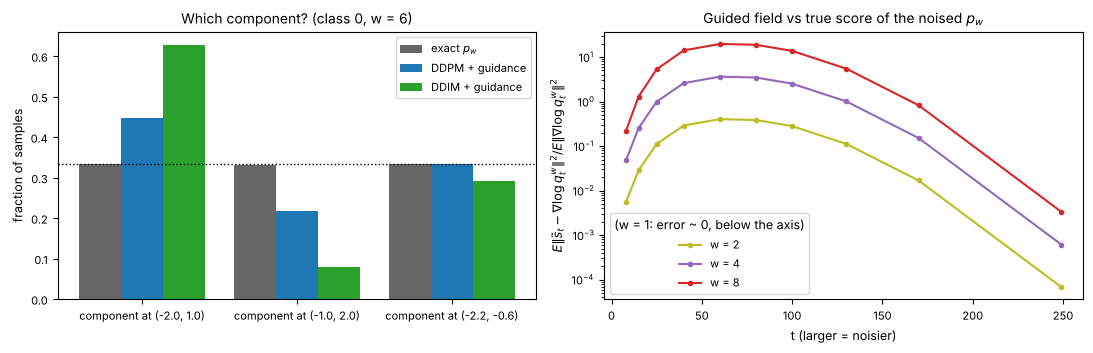

In [15]:
def noised_grid(x_t, pts, probs, abar, chunk=1024):
    """Score and log-density (up to a constant) of sum_j m_j N(x; sqrt(abar) g_j, (1 - abar) I):
    the forward-noised tabulated density, evaluated at the points x_t."""
    keep = probs > probs.max() * 1e-12                      # drop cells with negligible mass
    P, log_m = pts[keep], probs[keep].log()
    scores, log_dens = [], []
    for i in range(0, len(x_t), chunk):
        q = x_t[i:i + chunk].double()
        log_r = log_m[None] - torch.cdist(q, math.sqrt(abar) * P).pow(2) / (2 * (1 - abar))
        log_dens.append(torch.logsumexp(log_r, dim=1))
        r = torch.softmax(log_r, dim=1)                     # posterior over grid cells given x_t
        scores.append((math.sqrt(abar) * r @ P - q) / (1 - abar))   # Tweedie: (sqrt(abar) E[x0|x_t] - x_t) / (1-abar)
    return torch.cat(scores), torch.cat(log_dens)


T_MIS = [8, 25, 60, 130, 249] if FAST else [8, 15, 25, 40, 60, 80, 100, 130, 170, 249]
W_MIS = [1.0, 2.0, 4.0, 8.0]
N_XT = 30 if FAST else 50                                   # x_t quadrature grid: N_XT x N_XT points
g_xt = torch.linspace(-4.5, 4.5, N_XT, dtype=torch.float64)
xt_grid = torch.stack([a.flatten() for a in torch.meshgrid(g_xt, g_xt, indexing="xy")], 1)
t0 = time.time()
mismatch = {}
for w in W_MIS:
    # 100 x 100 cells suffice: finer grids (try n=200, N_XT=100) change these numbers by about 1%, but run much slower
    pts_w, probs_w, _ = tilted_density_grid(Y_TILT, w, n=100)
    errs = []
    for t in T_MIS:
        ab = abar_at(t)
        s_true, log_q = noised_grid(xt_grid, pts_w, probs_w, ab)
        quad_w = torch.softmax(log_q, 0)                    # quadrature weights ∝ q^w_t(x_t) on the x_t grid
        full, per_class = noised_mixtures(ab)
        s_guided = (1 - w) * full.score(xt_grid) + w * per_class[Y_TILT].score(xt_grid)
        errs.append(((quad_w * (s_guided - s_true).pow(2).sum(1)).sum()
                     / (quad_w * s_true.pow(2).sum(1)).sum()).item())
    mismatch[w] = np.array(errs)
print(f"quadrature: {time.time() - t0:.0f}s")
print(f"control w=1 (guided field IS the true score): max relative error {mismatch[1.0].max():.1e}")
assert mismatch[1.0].max() < 1e-6

# component occupancy: which class-0 component does each sample belong to?
occ = {"exact $p_w$": grid_occupancy(tw["pts"], tw["probs"], Y_TILT).numpy(),
       "DDPM + guidance": component_occupancy(tw["ddpm"], Y_TILT).numpy(),
       "DDIM + guidance": component_occupancy(tw["ddim"], Y_TILT).numpy()}
means0 = class_gmms[Y_TILT].means.numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bar_w = 0.27
for i, (name, o) in enumerate(occ.items()):
    axes[0].bar(np.arange(3) + (i - 1) * bar_w, o, width=bar_w, label=name, color=["0.4", "tab:blue", "tab:green"][i])
axes[0].set_xticks(range(3), [f"component at ({m[0]:.1f}, {m[1]:.1f})" for m in means0])
axes[0].axhline(1 / 3, color="k", ls=":", lw=1)
axes[0].set(ylabel="fraction of samples", title=f"Which component? (class {Y_TILT}, w = {W_TILT:g})")
axes[0].legend()
for w, c in zip(W_MIS[1:], ["tab:olive", "tab:purple", "tab:red"]):
    axes[1].semilogy(T_MIS, mismatch[w], "o-", ms=3, color=c, label=f"w = {w:g}")
axes[1].set(xlabel="t (larger = noisier)", ylabel="$E\\|\\tilde s_t-\\nabla\\log q^w_t\\|^2 / E\\|\\nabla\\log q^w_t\\|^2$",
            title="Guided field vs true score of the noised $p_w$")
axes[1].legend(title="(w = 1: error ~ 0, below the axis)")
plt.tight_layout()
plt.show()

**Left:** $p_w$ splits the mass equally over the three components, as $p(x\mid y{=}0)$ does. The guided samplers
do not. The top component at $(-1,2)$, the one reaching furthest towards the other classes, loses much of its
share (DDIM: almost all of it). The early push is "to the left", and it decides which component a sample joins.
**Right:** the guided field departs from the true tilted score mostly at **intermediate noise levels**. The
departure vanishes as $t\to0$ (at $\sigma=0$ the guided field is exactly $\nabla\log p_w$), vanishes again at very
high noise (both fields $\to -x$), and grows rapidly with $w$.

**Take-aways from this box.**
* Treat $w$ as a *knob judged by sample quality*, not as a principled temperature. Do not use guided samples where
  calibrated samples matter, e.g. as posterior samples for scientific inverse problems.
* The sampler matters under guidance: DDPM and DDIM produce different distributions even with perfect scores.
* If you genuinely need $p_w$, add correction: MCMC (e.g. Langevin steps using the $t\approx0$ field, which *is*
  the score of $p_w$) or sequential Monte Carlo reweighting. Local MCMC fixes shapes quickly, but the weights of
  separated modes only very slowly (Exercise 4).

These effects are analysed rigorously by Chidambaram et al. (2024), *What does guidance do? A fine-grained
analysis in a simple setting*, and by Bradley & Nakkiran (2024), *Classifier-free guidance is a
predictor-corrector*. The former proves, in simple mixture settings, that guidance does not sample the tilted
distribution and that strong guidance pushes samples towards the boundary of the class's support. The latter
proves that the DDPM and DDIM versions of CFG differ, and it makes the "built-in Langevin corrector" precise. In
the continuous-time limit, DDPM with CFG at scale $w$ is equivalent to a predictor–corrector scheme. The predictor
is a DDIM (probability-flow) step for the plain *conditional* $q_t(x\mid y)$. The corrector is Langevin dynamics
targeting $q_t(x)^{1-\gamma}\,q_t(x\mid y)^{\gamma}$ with $\gamma=2w-1$, not $w$. One line shows where $2w-1$
comes from. Write the forward SDE as $dx=f\,dt+g\,dW$ and let $s_u,s_c$ be the unconditional and conditional
scores. The guided reverse SDE has drift $f-g^2\tilde s_t$ and noise $g\,d\bar W$. Subtracting the conditional
probability-flow drift $f-\tfrac12 g^2 s_c$ leaves
$$-\tfrac12 g^2\big[2(1-w)\,s_u+(2w-1)\,s_c\big]\,dt+g\,d\bar W ,$$
which (time runs backwards, $dt<0$) is a Langevin step of size $g^2|dt|$ on the $(2w-1)$-powered density; the
coefficients $2(1-w)$ and $2w-1$ sum to 1. Their analysis covers the DDPM version only. DDIM has no such corrector,
consistent with it ending up even further from $p_w$ here.

## 5 · Class-conditional MNIST: the training recipe

Scaling up changes nothing conceptually. The conditional U-Net is `dm.UNet(n_classes=10, ...)`: a learned
embedding of the label, with one extra row for the null label 10, is added to the time embedding and enters
every residual block through FiLM. Training is notebook 05's loop with labels and label dropout. In
`dm.train_diffusion` this is just `labels=..., p_uncond=...`, which computes exactly our `cfg_training_loss`
(checked in Section 3).

Practical details:
* $p_\text{uncond}=0.1$ here. Too small, and the unconditional branch, hence $\epsilon_u$, is poor. Too large,
  and the conditional branch gets less data.
* Train exactly as long as an unconditional model. The extra cost of CFG is paid at *sampling* time.
* Below, a CPU gets 200 steps: enough to watch the recipe run (the loss falls from 1 to a few percent), far too
  few to sample from. Notebook 05 showed how sample quality develops with training. On a CUDA GPU the default
  is 4000 steps (~2–3 min). The checkpoint used next was trained with the same recipe for much longer; the
  loading cell prints for how many steps.

In [16]:
torch.set_num_threads(N_THREADS)   # back to all threads for the U-Net

x_mnist, y_mnist = dm.load_mnist(train=True)
x_mnist_test, y_mnist_test = dm.load_mnist(train=False)
MNIST_STEPS = 5 if FAST else (4000 if device.type == "cuda" else 200)
DDIM_STEPS = 5 if FAST else 30          # DDIM steps for the MNIST figures (2 NFE each when guided)

dm.seed_everything(0)
mnist_sched = dm.NoiseSchedule(1000, "linear", device=device)
my_unet = dm.UNet(n_classes=10, **dm.MNIST_RECIPE).to(device)
print(f"conditional U-Net: {dm.count_params(my_unet) / 1e6:.2f}M parameters "
      f"(class embedding: {my_unet.class_emb.weight.shape[0]} rows = 10 digits + null)")
t0 = time.time()
run = dm.train_diffusion(my_unet, x_mnist, mnist_sched, labels=y_mnist, p_uncond=0.1, steps=MNIST_STEPS,
                         batch_size=64, lr=2e-4, amp=USE_AMP, progress=False, log_every=max(1, MNIST_STEPS // 5))
my_unet_ema = run["ema"].model
print(f"{MNIST_STEPS} steps in {time.time() - t0:.0f}s ({MNIST_STEPS / (time.time() - t0):.1f} steps/s on {device})")

conditional U-Net: 1.19M parameters (class embedding: 11 rows = 10 digits + null)


step     40 | loss 0.9605


step     80 | loss 0.6673


step    120 | loss 0.2291


step    160 | loss 0.0559


step    200 | loss 0.0429
200 steps in 121s (1.6 steps/s on cpu)


To sample with guidance on images, we write the sampler out once more: deterministic DDIM (notebook 04) with
CFG, plus the practical variants used later (negative label, guidance interval, CFG-rescale). We verify it
against `dm.ddim_sample`. Two numerical details:
* the network runs under bfloat16 autocast for speed, but $\epsilon_c-\epsilon_u$ is computed in float32,
  because it is a small difference of large numbers and $w$ amplifies its rounding error;
* outside a guidance interval ($w_t=1$) only the conditional pass is needed, which saves NFEs.

In [17]:
@torch.no_grad()
def guided_ddim(model, schedule, x_T, y, w, *, n_steps=50, y_neg=None, interval=None, rescale=0.0, amp=USE_AMP):
    """Deterministic DDIM with classifier-free guidance. Returns the final (unclipped) sample.
    y_neg    : negative label used in place of the null label (None = plain CFG)
    interval : (t_lo, t_hi): guide only for t_lo <= t <= t_hi; elsewhere use the plain conditional (w = 1)
    rescale  : CFG-rescale factor phi in [0, 1] (0 = off)."""
    ts = np.unique(np.linspace(0, schedule.T - 1, n_steps).round().astype(int))[::-1]   # same grid as dmtools
    y_neg = torch.full_like(y, model.n_classes) if y_neg is None else y_neg
    x = x_T.clone()
    for i, t in enumerate(ts):
        ab = schedule.alpha_bars[t]
        ab_prev = schedule.alpha_bars[ts[i + 1]] if i + 1 < len(ts) else torch.ones((), device=x.device)
        w_t = w if (interval is None or interval[0] <= t <= interval[1]) else 1.0
        ctx = torch.autocast(x.device.type, dtype=torch.bfloat16) if amp else contextlib.nullcontext()
        if w_t == 1.0:                                       # plain conditional: 1 NFE
            with ctx:
                eps_c = model(x, torch.full((len(x),), int(t), device=x.device), y).float()
            eps = eps_c
        else:                                                # guided: cond + neg/uncond in one batch (2 NFE)
            with ctx:
                out = model(torch.cat([x, x]), torch.full((2 * len(x),), int(t), device=x.device),
                            torch.cat([y, y_neg]))
            eps_c, eps_n = out.float().chunk(2)              # combine in float32
            eps = eps_n + w_t * (eps_c - eps_n)
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        if rescale > 0 and w_t != 1.0:
            # CFG-rescale: match the per-sample std of the guided x0-prediction to that of the conditional one
            x0_c = (x - (1 - ab).sqrt() * eps_c) / ab.sqrt()
            dims = tuple(range(1, x.ndim))
            x0 = rescale * x0 * (x0_c.std(dim=dims, keepdim=True) / x0.std(dim=dims, keepdim=True)) + (1 - rescale) * x0
            eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()     # keep eps consistent with the modified x0
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps   # DDIM step (eta = 0)
    return x


# check against dmtools in float32
x_T_chk = torch.randn(10, 1, 28, 28, device=device, generator=make_gen(0))
y_chk = torch.arange(10, device=device)
mine = guided_ddim(my_unet_ema, mnist_sched, x_T_chk, y_chk, 3.0, n_steps=10, amp=False)
ref = dm.ddim_sample(my_unet_ema, mnist_sched, x_T_chk.shape, n_steps=10, y=y_chk, guidance_scale=3.0, x_T=x_T_chk)
print(f"guided_ddim vs dm.ddim_sample: max |diff| = {(mine - ref).abs().max().item():.1e}")
assert torch.allclose(mine, ref, atol=1e-3)

guided_ddim vs dm.ddim_sample: max |diff| = 2.3e-05


## 6 · Guidance on MNIST: the scale $w$

From here on we use a longer-trained model of the same recipe: the reference checkpoint `mnist_unet_cond.pt`
when it is available, otherwise a shorter run saved with this notebook (the cell prints which one, and for how
many steps it was trained). The MNIST classifier from `dmtools` serves as an *evaluator*; it plays no role in
sampling.

In [18]:
REF_CKPT = dm.CKPT_DIR / "mnist_unet_cond.pt"   # reference model, made by pretrain_checkpoints.py (or by dm, below)
OWN_CKPT = dm.CKPT_DIR / "06_mnist_cond.pt"     # same recipe, fewer steps, made while writing this notebook
if REF_CKPT.exists() or device.type == "cuda":
    # Loads the reference checkpoint. On a CUDA GPU without it, dmtools trains and caches it first (~10 min),
    # and notebook 07 then reuses the cached model.
    model, ref_sched = dm.load_or_train_mnist_model(conditional=True, device=device, amp=USE_AMP)
    assert torch.allclose(ref_sched.alpha_bars, mnist_sched.alpha_bars)
elif OWN_CKPT.exists():
    # Without a GPU, training the reference model here would take well over half an hour
    # (create it once with `python pretrain_checkpoints.py --only cond`), so we use the shorter run.
    ck = torch.load(OWN_CKPT, map_location=device, weights_only=True)
    model = dm.UNet(**ck["config"]).to(device).eval()
    model.load_state_dict(ck["ema"])
    print(f"{REF_CKPT.name} not found; loaded {OWN_CKPT.name} (same recipe, EMA weights after {ck['steps']} steps)")
else:
    print(f"no conditional checkpoint found: using the briefly trained in-notebook model instead. "
          "The results below will be poor until you create one with `python pretrain_checkpoints.py --only cond`.")
    model = my_unet_ema
clf = dm.load_or_train_classifier(device=device)

mnist_unet_cond.pt not found; loaded 06_mnist_cond.pt (same recipe, EMA weights after 4500 steps)


A grid of digits 0–9 (rows) for increasing $w$ (panels). Within a row, the three columns of every panel start
from the **same** three noise images, so you can follow one sample as $w$ grows.

5 x 30 samples (DDIM-30, 2 NFE/step) in 25s


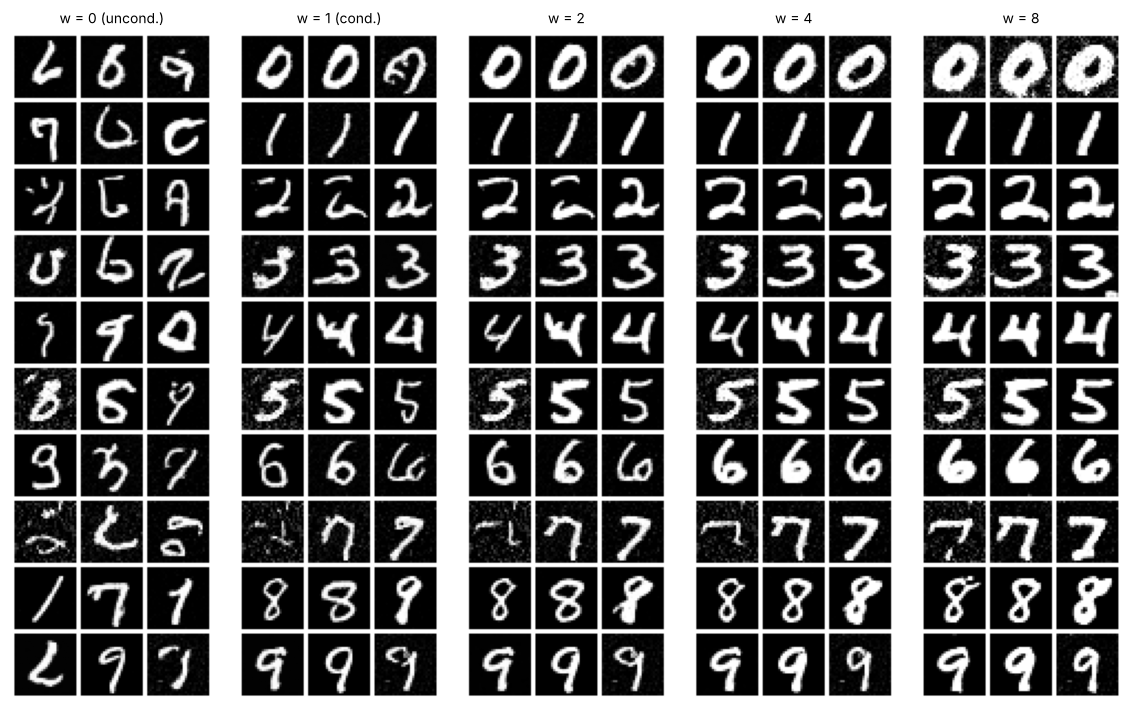

In [19]:
W_GRID = [0.0, 1.0, 2.0, 4.0, 8.0]
K = 1 if FAST else 3
y_grid = torch.arange(10, device=device).repeat_interleave(K)
x_T_grid = torch.randn(len(y_grid), 1, 28, 28, device=device, generator=make_gen(2))
t0 = time.time()
grid_samples = {w: guided_ddim(model, mnist_sched, x_T_grid, y_grid, w, n_steps=DDIM_STEPS).float().cpu()
                for w in W_GRID}
print(f"{len(W_GRID)} x {len(y_grid)} samples (DDIM-{DDIM_STEPS}, 2 NFE/step) in {time.time() - t0:.0f}s")
fig, axes = plt.subplots(1, len(W_GRID), figsize=(2.3 * len(W_GRID), 7))
for ax, w in zip(axes, W_GRID):
    dm.show_images(grid_samples[w], nrow=K, ax=ax,
                   title=f"w = {w:g}" + (" (uncond.)" if w == 0 else " (cond.)" if w == 1 else ""))
plt.tight_layout()
plt.show()

* $w=0$ ignores the label (the row index means nothing). $w=1$ samples $p(x\mid y)$. Most digits are right,
  some are ambiguous or wrong.
* Raising $w$ makes the digits cleaner and more "prototypical": samples that are noisy or ambiguous at $w=1$
  often turn into clean, confident digits. Samples also become *more alike*: the three columns of a row tend to
  converge in style.
* At large $w$ the strokes get thick and blob-like, and grainy artefacts can appear in the background. This
  **over-saturation** happens because the guided
  prediction extrapolates *past* the conditional one, $\tilde\epsilon=\epsilon_c+(w-1)(\epsilon_c-\epsilon_u)$, so
  $\hat x_0$ is pushed beyond the data range, and the excess survives into the final sample.

### 6.1 The fidelity–diversity trade-off

We quantify this with the MNIST classifier as an evaluator:
* **fidelity**: accuracy (classifier's top class = requested digit) and mean confidence $p_\text{clf}(y\mid x)$;
* **diversity**: mean pairwise distance between the classifier's 128-d penultimate-layer features of samples of
  the same requested digit, relative to the same quantity for real test digits (1 = as diverse as real data);
* **over-saturation**, two ways: the amount of **ink** (mean intensity of the clipped image) relative to real
  digits, which grows when strokes get bolder; and the fraction of raw, unclipped pixels **far beyond white**
  ($x>1.5$, where the data stop at 1). We look only at the bright side, because an imperfect model's background
  pixels hover slightly below $-1$ at any $w$.

All guidance scales share the same starting noise (common random numbers), so the curves are smooth.

In [20]:
@torch.no_grad()
def feature_diversity(x, y):
    """Mean pairwise distance of classifier features within each class, averaged over classes."""
    # .cpu(): torch.pdist has no Apple-MPS kernel, and a few hundred 128-d feature vectors are cheap on the CPU
    feats = clf.features(x.clamp(-1, 1)).float().cpu()
    y = y.cpu()
    return np.mean([torch.pdist(feats[y == c]).mean().item() for c in range(10) if (y == c).sum() > 1])


def ink(x):
    """Mean pixel intensity in [0, 1] of the clipped images (how much of the canvas is stroke)."""
    return ((x.clamp(-1, 1) + 1) / 2).mean().item()


@torch.no_grad()
def digit_metrics(x, y):
    """Fidelity / diversity / over-saturation of generated digits x (B,1,28,28) with requested labels y."""
    probs = torch.softmax(clf(x.clamp(-1, 1)), dim=1)
    return dict(acc=(probs.argmax(1) == y).float().mean().item(),
                conf=probs[torch.arange(len(y)), y].mean().item(),
                div=feature_diversity(x, y) / REAL_DIV,          # 1 = as diverse as real test digits
                ink=ink(x) / REAL_INK,                           # 1 = as much ink as real test digits
                over=(x > 1.5).float().mean().item())            # raw pixels far beyond white (data max = 1)


n_real = 20 if FAST else 100
real_idx = torch.cat([torch.where(y_mnist_test == c)[0][:n_real] for c in range(10)])
x_real, y_real = x_mnist_test[real_idx].to(device), y_mnist_test[real_idx].to(device)
REAL_DIV = feature_diversity(x_real, y_real)       # pairwise distances are unbiased, so n_real need not match
REAL_INK = ink(x_real)
real_m = digit_metrics(x_real, y_real)
print(f"real test digits: accuracy {real_m['acc']:.3f}, confidence {real_m['conf']:.3f}, ink {REAL_INK:.3f}")

W_TRICK = 6.0                       # used again in 6.2
W_SWEEP = [0.0, 1.0, W_TRICK] if FAST else [0.0, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0]
N_PER_DIGIT = 2 if FAST else 10
SWEEP_STEPS = 4 if FAST else 20
y_sweep = torch.arange(10, device=device).repeat_interleave(N_PER_DIGIT)
x_T_sweep = torch.randn(len(y_sweep), 1, 28, 28, device=device, generator=make_gen(3))
t0 = time.time()
sweep, sweep_x = {}, {}
for w in W_SWEEP:
    sweep_x[w] = guided_ddim(model, mnist_sched, x_T_sweep, y_sweep, w, n_steps=SWEEP_STEPS)
    sweep[w] = digit_metrics(sweep_x[w], y_sweep)
print(f"sweep: {len(W_SWEEP)} scales x {len(y_sweep)} samples (DDIM-{SWEEP_STEPS}) in {time.time() - t0:.0f}s")
print("    w   accuracy  confidence  rel.diversity  rel.ink  % px > 1.5")
for w, m in sweep.items():
    print(f"{w:5.1f}   {m['acc']:7.3f}   {m['conf']:9.3f}   {m['div']:12.3f}   {m['ink']:6.2f}   {100 * m['over']:9.2f}")

real test digits: accuracy 0.986, confidence 0.970, ink 0.124


sweep: 9 scales x 100 samples (DDIM-20) in 395s
    w   accuracy  confidence  rel.diversity  rel.ink  % px > 1.5
  0.0     0.100       0.100          1.569     1.12        0.03
  1.0     0.950       0.929          1.087     1.11        0.03
  1.5     0.990       0.984          0.958     1.17        0.04
  2.0     1.000       0.996          0.911     1.24        0.04
  3.0     1.000       1.000          0.839     1.36        0.05
  4.0     1.000       1.000          0.780     1.47        0.09
  6.0     1.000       1.000          0.705     1.65        0.20
  8.0     1.000       1.000          0.650     1.81        0.65
 12.0     1.000       0.998          0.581     2.11        3.71


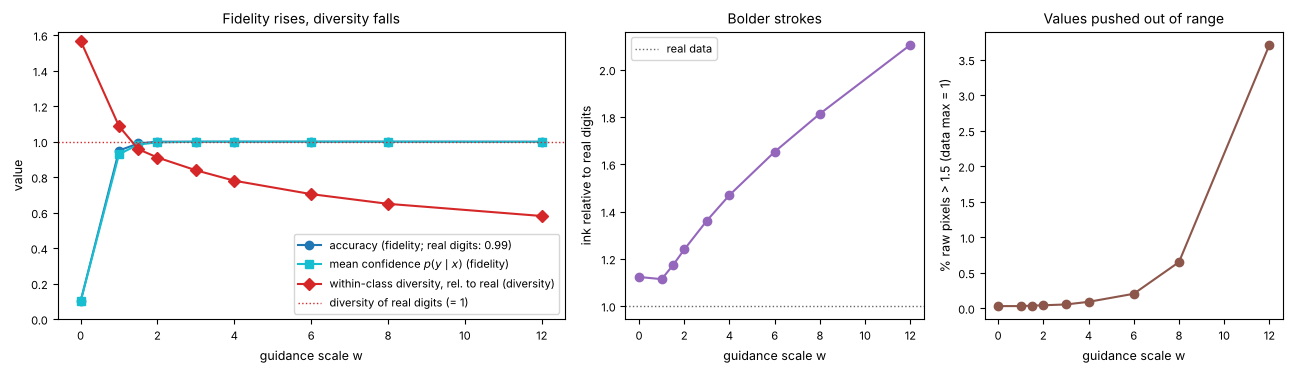

In [21]:
ws = np.array(W_SWEEP)
get = lambda k: np.array([sweep[w][k] for w in W_SWEEP])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.7, 1, 1]))
ax = axes[0]
ax.plot(ws, get("acc"), "o-", color="tab:blue", label=f"accuracy (fidelity; real digits: {real_m['acc']:.2f})")
ax.plot(ws, get("conf"), "s-", color="tab:cyan", label="mean confidence $p(y\\mid x)$ (fidelity)")
ax.plot(ws, get("div"), "D-", color="tab:red", label="within-class diversity, rel. to real (diversity)")
ax.axhline(1.0, color="tab:red", ls=":", lw=1, label="diversity of real digits (= 1)")
ax.set(xlabel="guidance scale w", ylabel="value", title="Fidelity rises, diversity falls",
       ylim=(0, max(1.1, get("div").max() + 0.05)))
ax.legend(loc="lower right")
axes[1].plot(ws, get("ink"), "o-", color="tab:purple")
axes[1].axhline(1.0, color="0.4", ls=":", lw=1, label="real data")
axes[1].set(xlabel="guidance scale w", ylabel="ink relative to real digits", title="Bolder strokes")
axes[1].legend()
axes[2].plot(ws, 100 * get("over"), "o-", color="tab:brown")
axes[2].set(xlabel="guidance scale w", ylabel="% raw pixels > 1.5 (data max = 1)", title="Values pushed out of range")
plt.tight_layout()
plt.show()

The classic CFG trade-off. Fidelity climbs steeply from $w=0$ to a few, then plateaus. Diversity falls
steadily as $w$ grows. Past the plateau, increasing $w$ buys almost no fidelity and keeps costing diversity, while
the strokes get bolder (more ink) and more raw pixel values are pushed far beyond the data range.

If the ink curve starts above 1 even without guidance, the model draws slightly bolder digits than the data or
leaves faint background speckle, both signs of limited training. What matters here is how ink grows with $w$.

A caveat on the diversity metric: at small $w$ it can exceed the real-data level. Some samples are then garbled
or show the wrong digit, and such samples lie far from the class in feature space, so they count as "diverse".
Diversity metrics only mean something alongside fidelity metrics, which is why papers plot
precision/recall or FID/IS curves against $w$ rather than a single number.

**Practical guidance on $w$** (diffusers convention $\tilde\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$;
some papers write $1+w$ for the same thing):
* The best $w$ depends on the model, the sampler, the number of steps and the metric. Measure it; there is no
  universal value. Class-conditional ImageNet models typically use $w$ around 1.5–4. Stable Diffusion's default
  is 7.5, with 5–9 common. Text conditioning is a much weaker signal per pixel, so larger scales are needed.
* **Over-saturation** at large $w$ comes from $\hat x_0$ leaving the data range. Clipping $\hat x_0$ to $[-1,1]$
  (notebook 05) or Imagen's dynamic thresholding (Saharia et al. 2022) limits it.
* **Guidance interval / schedule.** Guidance at high noise mostly reduces diversity (it decides the global layout
  early, as Section 4 showed), and at low noise it is mostly unnecessary. Kynkäänniemi et al. (2024) apply
  it only in a middle range of noise levels. That also saves NFEs, because outside the interval one pass suffices.
* **CFG-rescale** (Lin et al. 2024): rescale the guided prediction so its per-sample standard deviation
  matches the conditional prediction's, then blend with factor $\phi\approx0.7$. This counteracts the "burnt",
  high-contrast look. We apply it to $\hat x_0$; diffusers applies it to the $\epsilon$-prediction.
* **Cost:** CFG doubles the NFE per step. Distilled models (e.g. guidance-distilled or adversarially distilled
  ones) bake the guided prediction into a single network pass.

### 6.2 Trying the tricks

We compare plain CFG at $w=6$ with the same $w$ applied only in an interval of noise levels, and with CFG-rescale.
These use the same starting noise as the sweep. Whether a trick helps is an empirical question that depends on
the model and data, so read the numbers rather than assuming.

interval t in [60, 600]  <=>  noise-to-signal sigma in [0.21, 6.17]


                             accuracy  confidence  rel.diversity  rel.ink  % px > 1.5
w = 1 (no guidance)            0.950       0.929          1.087     1.11        0.03
w = 6                          1.000       1.000          0.705     1.65        0.20
w = 6, interval                1.000       0.997          0.869     1.36        0.06
w = 6, rescale φ=0.7           1.000       1.000          0.762     1.67        0.00


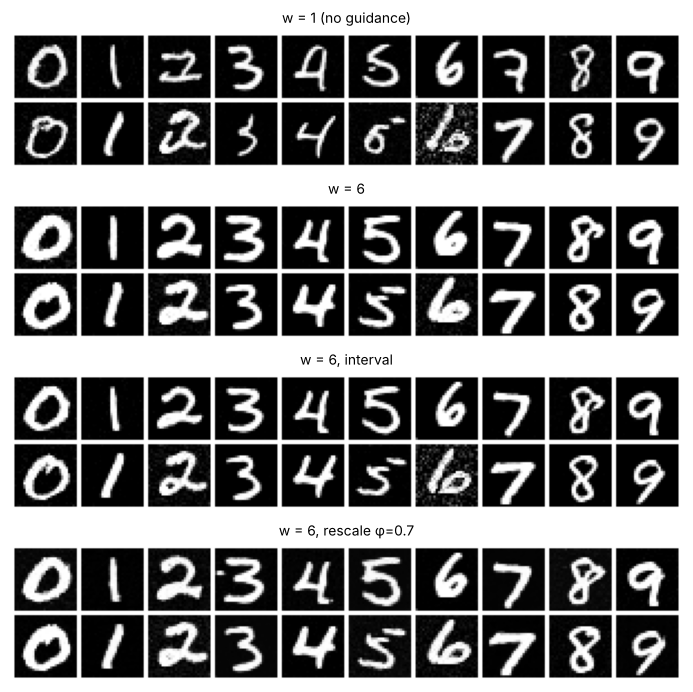

In [22]:
INTERVAL = (60, 600)   # t range in which guidance is applied (out of T = 1000)
sig = lambda t: math.sqrt((1 - abar_at(t, mnist_sched)) / abar_at(t, mnist_sched))
print(f"interval t in [{INTERVAL[0]}, {INTERVAL[1]}]  <=>  noise-to-signal sigma in [{sig(INTERVAL[0]):.2f}, {sig(INTERVAL[1]):.2f}]")
configs = {f"w = {W_TRICK:g}, interval": dict(w=W_TRICK, interval=INTERVAL),
           f"w = {W_TRICK:g}, rescale φ=0.7": dict(w=W_TRICK, rescale=0.7)}
# plain w = 1 and w = W_TRICK were already sampled in the sweep, from the same x_T
trick_x = {"w = 1 (no guidance)": sweep_x[1.0], f"w = {W_TRICK:g}": sweep_x[W_TRICK]}
for name, kw in configs.items():
    trick_x[name] = guided_ddim(model, mnist_sched, x_T_sweep, y_sweep, n_steps=SWEEP_STEPS, **kw)
trick_m = {name: digit_metrics(x, y_sweep) for name, x in trick_x.items()}
print(f"{'':28s} accuracy  confidence  rel.diversity  rel.ink  % px > 1.5")
for name, m in trick_m.items():
    print(f"{name:28s} {m['acc']:7.3f}   {m['conf']:9.3f}   {m['div']:12.3f}   {m['ink']:6.2f}   {100 * m['over']:9.2f}")

show_idx = torch.cat([torch.where(y_sweep == c)[0][:2] for c in range(10)])   # 2 samples per digit
show_idx = torch.cat([show_idx[0::2], show_idx[1::2]])                          # row 1: 0..9, row 2: 0..9
fig, axes = plt.subplots(len(trick_x), 1, figsize=(7.0, 1.75 * len(trick_x)))
for ax, name in zip(axes, trick_x):
    dm.show_images(trick_x[name][show_idx].float().cpu(), nrow=10, ax=ax, title=name)
plt.tight_layout()
plt.show()

Read the table against the plain $w=6$ row:
* **Interval**: guiding only part of the trajectory is a weaker guidance overall, so it lands between $w=1$ and
  $w=6$ on fidelity *and* diversity, with less ink, and it costs fewer NFEs. The real question is whether it beats
  plain CFG *at equal fidelity*, i.e. lies above the trade-off curve of 6.1. Exercise 5 asks you to check.
* **Rescale** targets over-exposure directly. It mainly cuts the out-of-range pixel values (last column) and leaves
  fidelity and diversity roughly where plain $w=6$ puts them.

On MNIST the visual differences are modest. In large text-to-image models these tricks are standard, because
over-saturation and lost diversity are much more visible there.

## 7 · Negative prompts: guidance away from something

In CFG the unconditional prediction is the point we extrapolate *away from*. Nothing forces it to be
unconditional. Replace $\varnothing$ by a **negative** condition $y^-$:
$$\tilde\epsilon=\epsilon(x_t,y^-)+w\,\big(\epsilon(x_t,y)-\epsilon(x_t,y^-)\big)
\quad\Longleftrightarrow\quad
\tilde s_t=\nabla\log q_t(x_t\mid y^-)+w\,\nabla\log\frac{p_t(y\mid x_t)}{p_t(y^-\mid x_t)} ,$$
where $q_t(x_t)$ cancels in the ratio. The guidance direction is now the gradient of a **log-likelihood ratio**
between $y$ and $y^-$: towards $y$ *and* away from $y^-$. This is the "negative prompt" box of text-to-image UIs
(e.g. "blurry, extra fingers"), and it costs nothing extra: $y^-$ simply takes the place of $\varnothing$ in the
batch.

**A caveat worth deriving.** At every noise level $t$ the guided field is the log-gradient of
$$\underbrace{q_t(x\mid y)\Big[\tfrac{q_t(x\mid y)}{q_t(x)}\Big]^{w-1}}_{\text{null: }\;\le\;p(y)^{1-w}\,q_t(x\mid y)}
\qquad\text{vs.}\qquad
q_t(x\mid y)\Big[\tfrac{q_t(x\mid y)}{q_t(x\mid y^-)}\Big]^{w-1}.$$
With the null label, $q_t(x)=\sum_c p(c)\,q_t(x\mid c)\ge p(y)\,q_t(x\mid y)$, and for $w\ge1$ the exponent $1-w$
is $\le0$. So the function plain CFG climbs is bounded by a constant times the class density itself, at *every*
$t$. It has no high ground where class $y$ has negligible mass: guidance can re-weight the class, but it does not
pull samples out of it. A negative condition gives no such bound. Where $y^-$ has even less mass than $y$, the
ratio grows without limit, so strong negative guidance can push samples *out of* class $y$ altogether.
(The bound constrains the field, not the sampler's output, and it assumes exact scores. With learned scores,
Chidambaram et al. (2024) show that a large enough $w$ leads off the class's support even with the null label.)
In 2-D, exactly: ask for class 1, steering away from nothing (null) or from class 2, at two strengths.

class 1 requested            mean p(1|x)   mean p(2|x)   mean x-coordinate


w=3, negative = null              0.998       0.0022            +0.35
w=1.5, negative = class 2         0.859       0.0003            -0.63
w=3, negative = class 2           0.000       0.0000            -3.40


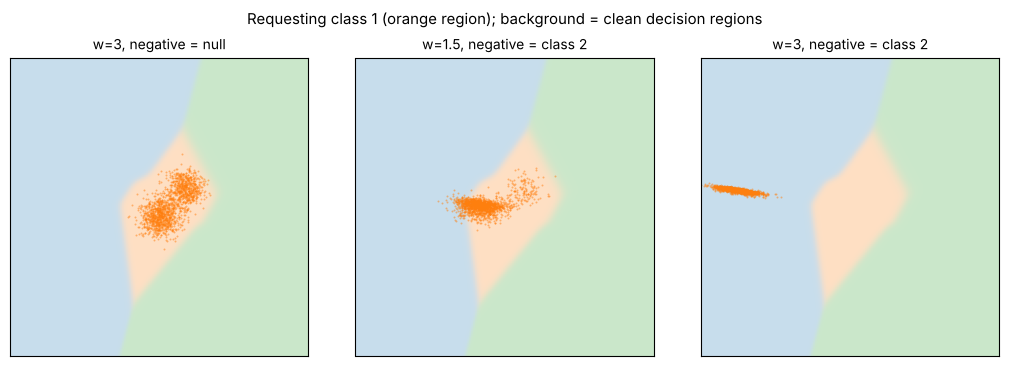

In [23]:
if device.type == "cpu":
    torch.set_num_threads(1)          # tiny 2-D computations again


class NegativeGuided(nn.Module):
    """Wraps an eps-model: forward(x, t, y) = eps(y_neg) + w (eps(y) - eps(y_neg)) via cfg_eps."""

    def __init__(self, base, w, y_neg_label):
        super().__init__()
        self.base, self.w, self.y_neg_label, self.n_classes = base, w, y_neg_label, base.n_classes

    def forward(self, x, t, y):
        return cfg_eps(self.base, x, t, y, self.w, y_neg=torch.full_like(y, self.y_neg_label))


lab_neg = torch.full((N_TILT,), 1)
neg_configs = {"w=3, negative = null": (3.0, NULL),
               "w=1.5, negative = class 2": (1.5, 2),
               "w=3, negative = class 2": (3.0, 2)}
neg_samples = {name: sample_2d(NegativeGuided(exact, w, neg), lab_neg, seed=30) for name, (w, neg) in neg_configs.items()}
torch.set_num_threads(N_THREADS)
print(f"{'class 1 requested':28s} mean p(1|x)   mean p(2|x)   mean x-coordinate")
wide_rgb = class_rgb_image(None, lim=4.5)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
for ax, (name, s) in zip(axes, neg_samples.items()):
    ax.imshow(wide_rgb, extent=[-4.5, 4.5, -4.5, 4.5], origin="lower", alpha=0.25)
    dm.scatter2d(s[SHOW], ax=ax, lim=4.5, s=2, alpha=0.5, c=CLASS_COLORS[1], title=name)
    probs = noisy_classifier_logprobs(s.double()).exp()
    print(f"{name:28s} {probs[:, 1].mean():10.3f}   {probs[:, 2].mean():10.4f}   {s[:, 0].mean():+14.2f}")
plt.suptitle("Requesting class 1 (orange region); background = clean decision regions", y=1.0)
plt.tight_layout()
plt.show()

With the null negative, class-1 samples stay inside class 1's region, consistent with the bound. With class 2 as
the negative, they are pushed specifically away from class 2 (green, right). A mild $w=1.5$ shifts them to the left,
mostly still inside class 1. $w=3$ overshoots: the samples leave class 1 entirely and pile up in a narrow streak
in class 0's territory. That point is
"maximally un-class-2", not "a typical class 1". In text-to-image practice negative prompts behave better because
typical negatives ("blurry", "low quality") overlap broadly with everything, but the overshoot is real.

Now on MNIST: we ask for an **8** (some 8s, with an open left side, resemble a 3), once with plain CFG and once
with **3** as the negative label, at a moderate scale.

48 samples each                mean p(8|x)   mean p(3|x)   accuracy
plain CFG (negative = null)         0.980         0.0165       0.98
negative label = 3                  0.968         0.0000       0.98


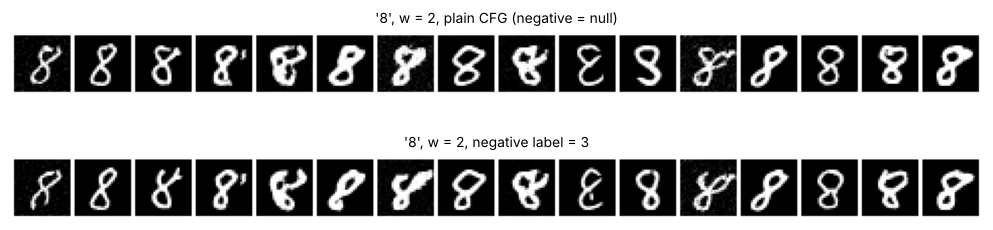

In [24]:
Y_POS, Y_NEG, W_NEG = 8, 3, 2.0
n_neg, n_show = (8, 8) if FAST else (48, 16)          # metrics on n_neg samples, show the first n_show
y_pos = torch.full((n_neg,), Y_POS, device=device)
x_T_neg = torch.randn(n_neg, 1, 28, 28, device=device, generator=make_gen(4))
neg_results = {"plain CFG (negative = null)":
                   guided_ddim(model, mnist_sched, x_T_neg, y_pos, W_NEG, n_steps=DDIM_STEPS),
               f"negative label = {Y_NEG}":
                   guided_ddim(model, mnist_sched, x_T_neg, y_pos, W_NEG, n_steps=DDIM_STEPS,
                               y_neg=torch.full_like(y_pos, Y_NEG))}
fig, axes = plt.subplots(2, 1, figsize=(10, 2.9))
print(f"{n_neg} samples each{'':16s}mean p({Y_POS}|x)   mean p({Y_NEG}|x)   accuracy")
for ax, (name, x) in zip(axes, neg_results.items()):
    dm.show_images(x[:n_show].float().cpu(), nrow=n_show, ax=ax, title=f"'{Y_POS}', w = {W_NEG:g}, {name}")
    with torch.no_grad():
        p = torch.softmax(clf(x.clamp(-1, 1)), 1)
    print(f"{name:30s} {p[:, Y_POS].mean():10.3f}   {p[:, Y_NEG].mean():12.4f}   "
          f"{(p.argmax(1) == Y_POS).float().mean():8.2f}")
plt.tight_layout()
plt.show()

Same starting noise in both rows. Most samples barely change, a few are visibly altered, and the evaluator's
$p(3\mid x)$ drops by a large factor. The price shows in $p(8\mid x)$, which can drop a little. Through
$\varnothing$, plain CFG pushes away from *all* other digits. The negative version pushes away from 3 only, and,
as in 2-D, nothing bounds it by $q_t(x\mid 8)$. Try `W_NEG = 4` or `8` and look at the *images* rather than the
printed numbers: the evaluator still calls most samples 8s, but the strokes bend into curly, open shapes that are
as un-3-like as possible. On MNIST the overshoot is subtler than in 2-D, but it is there.
The same mechanism, with several conditions, gives **compositional** generation (Exercise 6):
$\tilde\epsilon=\epsilon_u+\sum_i w_i(\epsilon_{c_i}-\epsilon_u)$, a product of experts with negative
weights allowed.

## Exercises

**Exercise 1 (label dropout).** Retrain the 2-D CFG network (Section 3) with `P_UNCOND = 0.0`, then with `0.5`.
Before running: which of $w=0$, $w=1$, $w=3$ and $w=10$ will still produce sensible samples in each case? In
particular, using Section 3's diagnosis of the $w=10$ collapse, predict what $p_\text{uncond}=0.5$ does to it.
Check with the $\epsilon$-error table, the MMD table and the figure.

<details><summary>Hint / solution</summary>

With $p_\text{uncond}=0$ the null embedding is never trained, so $\epsilon_u$ is garbage. $w=0$ samples garbage,
$w=1$ is fine (it never evaluates $\epsilon_u$: `dm.model_predictions` skips the second pass when $w=1$), and
$w=3$ is badly distorted because it extrapolates away from garbage. With $p_\text{uncond}=0.5$ the unconditional
branch sees more than three times as much data as with 0.15. Its error at small $t$ drops sharply, the error of
the implicit classifier $\epsilon_c-\epsilon_u$ drops several-fold, and the $w=10$ collapse of Section 3 largely
disappears. Meanwhile $\epsilon_c$ gets slightly worse, because the conditional branch now sees only half the
data. This confirms that the under-trained $\epsilon_u$ was the culprit. $p_\text{uncond}$ trades conditional
quality ($w=1$) against guided quality ($w\gg1$).
</details>

**Exercise 2 (negative guidance scale).** Use classifier guidance with $w=-2$ in Section 2. Predict where the
samples for class 1 will go, then check.

<details><summary>Hint / solution</summary>

The target at $t=0$ is $p(x)\,p(y\mid x)^{-2}$: points where class $y$ is *unlikely* are favoured, so samples
move into the other classes' territory. With $w<0$ the "guidance" is a repulsion from $y$. This is
the 2-D version of a negative prompt *without* a positive one.
</details>

**Exercise 3 (the wrong classifier).** In `ClassifierGuidedEps`, replace the noise-aware classifier by the
*clean* one evaluated at the noisy point (`noisy_classifier_logprobs(x64, None)`), sample with $w=1$, and compare
with the true $p(x\mid y)$ (MMD). Then evaluate the clean classifier at the Tweedie denoised point
$\hat x_0(x_t)=\big(x_t+(1-\bar\alpha_t)\nabla\log q_t(x_t)\big)/\sqrt{\bar\alpha_t}$ instead, with the score from
`noised_mixtures(ab)[0].score(x64)`, which is differentiable. *Before running*, predict which of the two will be
closer to $p(x\mid y)$. Then check (per-class MMD over a few seeds, and the component occupancy), and explain why
neither is exact.

<details><summary>Hint / solution</summary>

Both are clearly biased: their MMD to $p(x\mid y)$ is a few times the noise floor, whereas the noise-aware
classifier sits at the floor. The clean classifier at $x_t$ has the wrong geometry, because $x_t$ is a shrunken,
noisy version of $x_0$ and the clean decision boundaries do not apply to it. Most people predict that the
Tweedie plug-in fixes this. In this lab it is actually *worse*, on every seed, and it visibly re-weights
components. The reason is that the expectation does not commute with the non-linear classifier:
$p(y\mid\mathbb E[x_0\mid x_t])\neq\mathbb E[p(y\mid x_0)\mid x_t]$. At high noise $\hat x_0(x_t)$ collapses to the
data mean $\mathbb E[x_0]$, which here lies inside class 1's region (check:
`(gmm.weights[:, None] * gmm.means).sum(0)`). So the plug-in says "class 1" with near certainty for *every*
$x_t$, while the truth is close to $1/3$ each. It is most over-confident exactly where the true classifier is
most uncertain, and, as with strong guidance, the decisions forced at high noise re-weight the components. A
plausible-looking fix need not help: measure. This plug-in approximation underlies "universal guidance" and
DPS-style posterior sampling (notebook 07).
</details>

**Exercise 4 (is the Section 4 mismatch a discretisation error? can MCMC fix it?).** (a) Re-run the Section 4
comparison with a finer schedule: `fine = dm.NoiseSchedule(1000, "linear", device=device)`,
`sample_2d(ExactDenoiser(fine), lab_tilt, w=W_TILT, sampler="ddim", schedule=fine)`. Does the MMD to $p_w$
shrink? (b) Starting from the DDIM-guided samples, run unadjusted Langevin steps
$x\leftarrow x+\tfrac{\delta}{2}\tilde s_0(x)+\sqrt\delta\,z$ with the clean guided score
$\tilde s_0=(1-w)\nabla\log p(x)+w\nabla\log p(x\mid y)$ (`(1 - w) * gmm.score(x) + w * class_gmms[0].score(x)`),
which *is* $\nabla\log p_w$ (use $\delta=10^{-3}$). Track the MMD to $p_w$ and the component occupancy after 100,
500, 2000 and 5000 steps. Which gets fixed first: the shape of each blob or the component occupancy?

<details><summary>Hint / solution</summary>

(a) No: the mismatch is a property of the continuous-time guided dynamics, not of the step size. (b) Within a few
hundred steps the DDIM streaks relax into round blobs and the MMD drops a lot, while the occupancy has barely
moved. Mass has to hop between components across low-density valleys, and that takes thousands of steps here.
Escape times grow exponentially with the barrier height, and these components overlap, so the barriers are low.
For well-separated modes (e.g. different global layouts of an image) local MCMC would essentially never fix the
weights. That needs global moves or importance reweighting (SMC).
</details>

**Exercise 5 (find a better trade-off).** On MNIST, sweep the guidance interval (`interval=(t_lo, t_hi)`) or the
rescale factor $\phi$ at a few $w$. Plot confidence against diversity for each configuration, so every point is
one $(w,\text{trick})$ pair. Which configurations lie on the upper-right frontier? (Use the same `x_T_sweep` for
all.)

<details><summary>Hint / solution</summary>

Collect `digit_metrics` for, e.g., `w in [2, 4, 6, 8]` crossed with `interval in [None, (60, 600), (0, 400),
(200, 999)]`. Intervals that *exclude the highest noise levels* tend to keep more diversity for the same
fidelity, which is the main finding of Kynkäänniemi et al. (2024). Whether it holds for this small model is
exactly what the plot tells you.
</details>

**Exercise 6 (composition).** Modify `guided_ddim` to accept a list of labels and weights and use
$\tilde\epsilon=\epsilon_u+\sum_i w_i(\epsilon_{c_i}-\epsilon_u)$. Ask for "3" and "8" at once with $w_i=2$. What
distribution does this target (at $t=0$), and what do the samples look like?

<details><summary>Hint / solution</summary>

At $t=0$ the target is $p(x)\,p(3\mid x)^{w_1}p(8\mid x)^{w_2}$, a product of experts that favours images the
classifier finds compatible with *both* labels: 3/8 hybrids. For mutually exclusive classes this is
mostly off-manifold, so expect odd images. Compositions work better for attributes that can co-occur
(e.g. "red" and "car" in text-to-image).
</details>

## Key takeaways

* **Bayes' rule for scores**: $\nabla\log q_t(x\mid y)=\nabla\log q_t(x)+\nabla\log p_t(y\mid x)$. The classifier
  must be the *noise-aware* posterior $p_t(y\mid x_t)=\mathbb E[p(y\mid x_0)\mid x_t]$, not a clean classifier.
* **Conditioning a network** is trivial: add a label embedding to the time embedding and train as usual.
* **Classifier guidance** scales the classifier gradient by $w$ (an extra forward + backward per step).
  **CFG** gets the same effect from one network trained with label dropout:
  $\tilde\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$ at 2 NFE per step. With exact scores, the two are
  identical.
* Increasing $w$ trades **diversity for fidelity**. Beyond a few units it adds little fidelity and causes
  over-saturation. Choose $w$ by measurement. Guidance intervals, CFG-rescale and $\hat x_0$ thresholding
  soften the side effects.
* Guided sampling, even with exact scores, mostly **re-weights** modes, starving those near other classes. That
  is an effect of the guided *dynamics*, not of the tilted target $p(x)p(y\mid x)^w$, which barely re-weights
  well-separated modes. Learned CFG also **amplifies model error** by $w$. An over-smoothed $\epsilon_u$ in
  particular turns into over-sharpened, collapsed modes.
* Guided samplers do **not** sample $p(x)p(y\mid x)^w$: noising does not commute with tilting, guidance acts
  mostly at intermediate noise, and DDPM and DDIM give different results. Use $w$ as a quality knob, not as a
  calibrated temperature.
* **Negative prompts** replace $\varnothing$ by $y^-$ and follow the gradient of a likelihood ratio. Plain CFG
  climbs a function bounded by a multiple of $q_t(x\mid y)$; a negative prompt has no such bound, so strong
  negative guidance can overshoot out of the class.

## Further reading

* P. Dhariwal & A. Nichol (2021). *Diffusion Models Beat GANs on Image Synthesis.* arXiv:2105.05233. Classifier guidance.
* J. Ho & T. Salimans (2022). *Classifier-Free Diffusion Guidance.* arXiv:2207.12598.
* Y. Song et al. (2021). *Score-Based Generative Modeling through Stochastic Differential Equations.*
  arXiv:2011.13456. Conditional generation via Bayes' rule for scores (Sec. 5).
* A. Nichol et al. (2022). *GLIDE: Towards Photorealistic Image Generation and Editing with Text-Guided Diffusion
  Models.* arXiv:2112.10741. CFG vs CLIP guidance for text-to-image.
* C. Saharia et al. (2022). *Photorealistic Text-to-Image Diffusion Models with Deep Language Understanding*
  (Imagen). arXiv:2205.11487. Large guidance scales and dynamic thresholding.
* R. Rombach et al. (2022). *High-Resolution Image Synthesis with Latent Diffusion Models.* arXiv:2112.10752.
  Stable Diffusion, sampled with CFG.
* M. Chidambaram et al. (2024). *What does guidance do? A fine-grained analysis in a simple setting.* arXiv:2409.13074.
* A. Bradley & P. Nakkiran (2024). *Classifier-Free Guidance is a Predictor-Corrector.* arXiv:2408.09000.
* T. Kynkäänniemi et al. (2024). *Applying Guidance in a Limited Interval Improves Sample and Distribution Quality
  in Diffusion Models.* NeurIPS 2024. arXiv:2404.07724.
* S. Lin et al. (2024). *Common Diffusion Noise Schedules and Sample Steps are Flawed.* WACV 2024.
  arXiv:2305.08891. Introduces CFG-rescale.
* S. Dieleman (2022). *Guidance: a cheat code for diffusion models.* Blog post, sander.ai.
* Y. Song (2021). *Generative Modeling by Estimating Gradients of the Data Distribution.* Blog post (controllable
  generation section).